In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsRegressor,KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier,BaggingClassifier,AdaBoostClassifier,StackingClassifier

from sklearn.linear_model import Lasso,Ridge
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.model_selection import train_test_split,GridSearchCV,KFold,StratifiedKFold
from sklearn.preprocessing import LabelEncoder,OneHotEncoder,StandardScaler,PolynomialFeatures
from sklearn.metrics import mean_absolute_error,mean_squared_error, accuracy_score, r2_score,confusion_matrix,f1_score,recall_score,precision_score



In [4]:
dfl=pd.read_csv('loan_approval_dataset.csv')
dfl

,Age,Salary,Credit_Score,Loan_Amount,Loan_Term,Employment_Status,Residence_Type,Previous_Default,Loan_Approved
0,56,136748,584,38209,36 months,Employed,Owned,Yes,Yes
1,46,25287,815,27424,24 months,Self-Employed,Rented,No,Yes
2,32,146593,398,42396,12 months,Unemployed,Rented,Yes,Yes
3,60,54387,696,11370,24 months,Unemployed,Owned,No,No
4,25,28512,788,14528,12 months,Employed,Owned,No,No
...,...,...,...,...,...,...,...,...,...
995,22,49241,500,41020,24 months,Self-Employed,Owned,No,Yes
996,40,116214,423,12415,48 months,Self-Employed,Owned,No,Yes
997,27,64569,300,28155,36 months,Self-Employed,Rented,Yes,Yes
998,61,31745,490,48884,12 months,Self-Employed,Mortgage,No,Yes


In [5]:
#dfl.isnull().fillna(0,inplace=True)
#dfl

In [6]:
dfl.isnull().sum()

,0
Age,0
Salary,0
Credit_Score,0
Loan_Amount,0
Loan_Term,0
Employment_Status,0
Residence_Type,0
Previous_Default,0
Loan_Approved,0


In [7]:
for i in dfl.columns:
  if dfl[i].dtype=='object':
    le=LabelEncoder()
    dfl[i]=le.fit_transform(dfl[i])
dfl


,Age,Salary,Credit_Score,Loan_Amount,Loan_Term,Employment_Status,Residence_Type,Previous_Default,Loan_Approved
0,56,136748,584,38209,2,0,1,1,1
1,46,25287,815,27424,1,1,2,0,1
2,32,146593,398,42396,0,2,2,1,1
3,60,54387,696,11370,1,2,1,0,0
4,25,28512,788,14528,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...
995,22,49241,500,41020,1,1,1,0,1
996,40,116214,423,12415,3,1,1,0,1
997,27,64569,300,28155,2,1,2,1,1
998,61,31745,490,48884,0,1,0,0,1


In [8]:
x=dfl.iloc[:,:-1]
y=dfl.iloc[:,-1]
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [9]:
model=LogisticRegression()
model.fit(x_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [10]:
model=model.predict(x_test)
model

array([1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0,
       0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0,
       0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0,
       1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1,
       1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1,
       1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 1])

In [11]:
#Decision Tree
model= DecisionTreeClassifier()
model.fit(x_train,y_train)

DecisionTreeClassifier()

In [12]:
dfl.tail()

,Age,Salary,Credit_Score,Loan_Amount,Loan_Term,Employment_Status,Residence_Type,Previous_Default,Loan_Approved
995,22,49241,500,41020,1,1,1,0,1
996,40,116214,423,12415,3,1,1,0,1
997,27,64569,300,28155,2,1,2,1,1
998,61,31745,490,48884,0,1,0,0,1
999,19,46029,815,21964,1,0,0,1,0


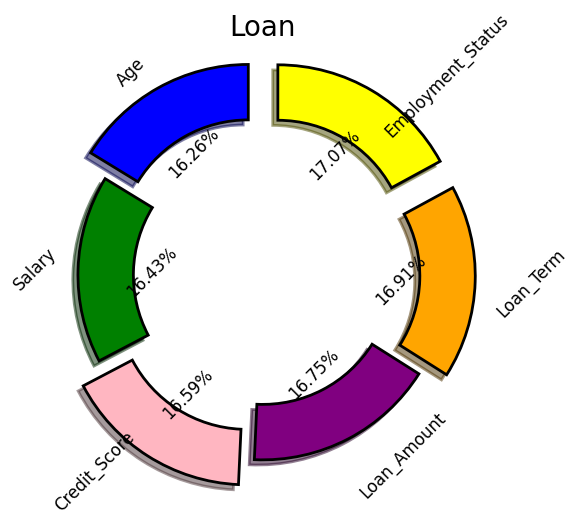

In [13]:
plt.figure(figsize=(6,6))
plt.pie([101,102,103,104,105,106],labels=['Age','Salary','Credit_Score','Loan_Amount','Loan_Term','Employment_Status'],autopct='%.2f%%',colors=['blue','green','lightpink','purple','orange','yellow'],shadow=True,
        explode=[0.16,0,0.16,0,0.15,0.16],
         startangle=90,
         radius=1,
        pctdistance=0.6,
        textprops={'color':'black','fontsize':12,'rotation':45},
        wedgeprops={'edgecolor':'black','linewidth':2,'width':0.3})
plt.title('Loan',fontsize=20,y=1)
plt.show()

In [14]:
y_pred=model.predict(x_test)
confusion_matrix(y_test,y_pred)

array([[46, 49],
       [54, 51]])

In [15]:
 recall_score(y_test,y_pred)

0.4857142857142857

/tmp/ipykernel_399/3277211825.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  hist=sns.histplot(x='Salary',data=dfl,bins=5,color='black',multiple='dodge',palette='rainbow',shrink=0.9)


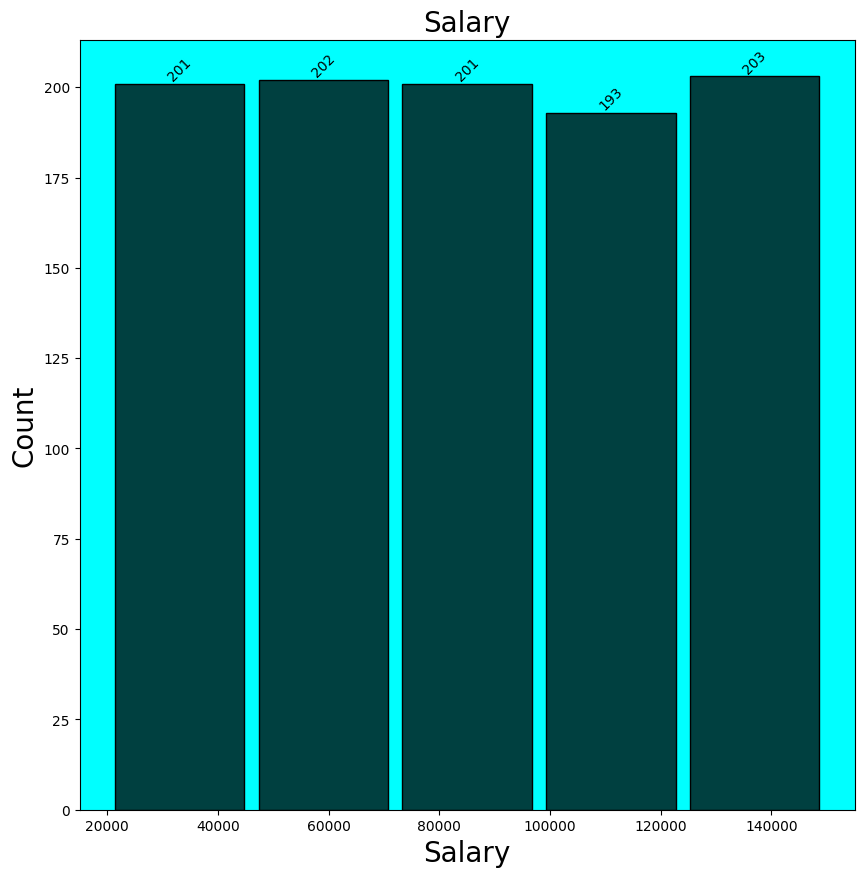

In [16]:

plt.figure(figsize=(10,10))
hist=sns.histplot(x='Salary',data=dfl,bins=5,color='black',multiple='dodge',palette='rainbow',shrink=0.9)
hist.figure.set_facecolor('white')
hist.figure.set_figheight(10)
hist.figure.set_figwidth(10)
plt.xlabel('Salary',fontsize=20)
plt.ylabel('Count',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Salary',fontsize=20,y=1)
for i in hist.containers:
    hist.bar_label(i,color='black',rotation=45,fontsize=10,label_type='edge')

plt.show()

In [17]:
model=Ridge(alpha=10)
alpha=[0.25,125,0.78]
model_new=GridSearchCV(model,param_grid={'alpha':alpha})
model_new.fit(x_train,y_train)


GridSearchCV(estimator=Ridge(alpha=10), param_grid={'alpha': [0.25, 125, 0.78]})

In [18]:
print(model_new.best_params_)
print(model_new.best_score_)

{'alpha': 125}
-0.01666609537029524


In [19]:
dfl=dfl.rename(columns={'Residence_Type':'Residence','Employment_Status':'Employment','Previous_Default':'Previous','Credit_Score':'Credit','Loan_Amount':'Loan'})
dfl

,Age,Salary,Credit,Loan,Loan_Term,Employment,Residence,Previous,Loan_Approved
0,56,136748,584,38209,2,0,1,1,1
1,46,25287,815,27424,1,1,2,0,1
2,32,146593,398,42396,0,2,2,1,1
3,60,54387,696,11370,1,2,1,0,0
4,25,28512,788,14528,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...
995,22,49241,500,41020,1,1,1,0,1
996,40,116214,423,12415,3,1,1,0,1
997,27,64569,300,28155,2,1,2,1,1
998,61,31745,490,48884,0,1,0,0,1


In [20]:
x=dfl.iloc[:,:-1]
y=dfl.iloc[:,-1]
kf=KFold(n_splits=5,shuffle=True,random_state=42)
ac=[]
for train_index,test_index in kf.split(x):
    x_train,x_test=x.iloc[train_index],x.iloc[test_index]
    y_train,y_test=y.iloc[train_index],y.iloc[test_index]
    model=LogisticRegression()
    model.fit(x_train,y_train)
    y_pred=model.predict(x_test)
    accuracy=accuracy_score(y_test,y_pred)
    ac.append(accuracy)
print(ac)


[0.535, 0.505, 0.47, 0.555, 0.455]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

In [21]:
model=DecisionTreeClassifier()
model.fit(x_train,y_train)


DecisionTreeClassifier()

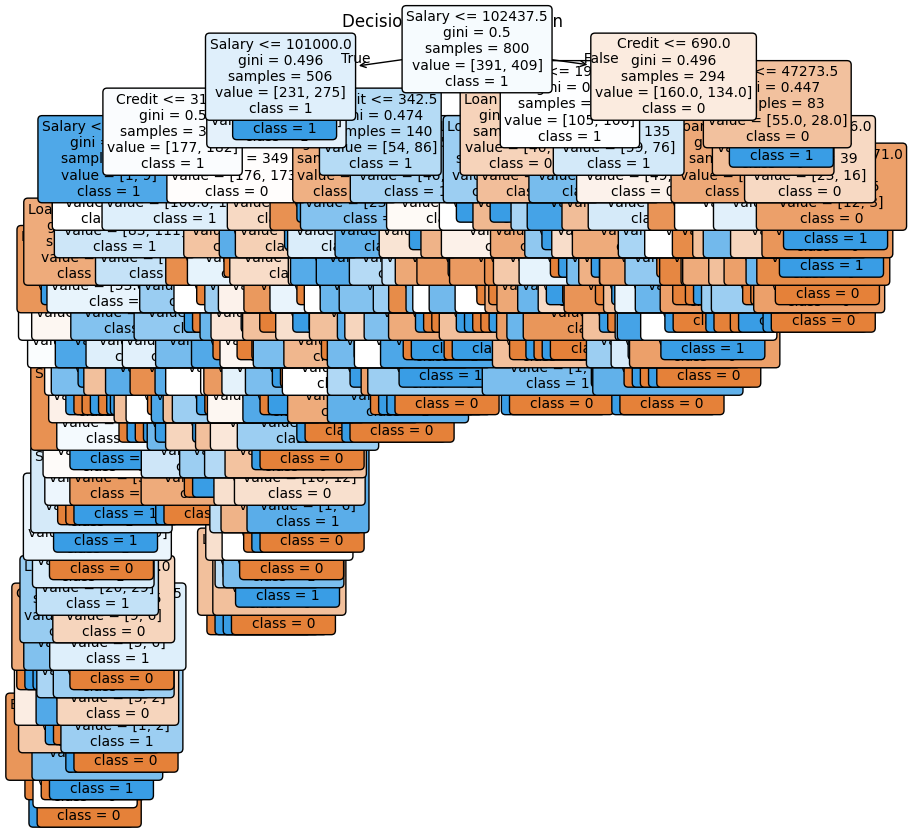

In [22]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plt.figure(figsize=(10,10))
plot_tree(model,feature_names=dfl.columns.tolist(),class_names=['0','1'],rounded=True,filled=True,fontsize=10)
plt.title('Decision Tree Visualization')
plt.xlabel('Features')
plt.ylabel('Tree Depth')
plt.gca().set_facecolor('cyan')
plt.gca().set_facecolor('yellow')
plt.show()

In [23]:
model=LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [24]:
model= LogisticRegression()
model.fit(x_train,y_train)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [25]:
model = DecisionTreeClassifier()
model.fit(x_train, y_train)

DecisionTreeClassifier()

In [26]:
y_pred=model.predict(x_test)
y_pred

array([0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1,
       1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       0, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0,
       1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1,
       0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1,
       0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0,
       0, 0])

In [27]:
dfl.describe()

,Age,Salary,Credit,Loan,Loan_Term,Employment,Residence,Previous,Loan_Approved
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,40.986000,85197.154000,576.329000,27161.882000,1.453000,1.050000,0.980000,0.468000,0.508000
std,13.497852,38105.636581,157.738607,12825.343062,1.114914,0.817416,0.819922,0.499225,0.500186
min,18.000000,20060.000000,300.000000,5138.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,29.000000,52237.250000,442.000000,16181.750000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,42.000000,84850.500000,576.000000,26633.500000,1.000000,1.000000,1.000000,0.000000,1.000000
75%,52.000000,117480.000000,709.750000,38002.000000,2.000000,2.000000,2.000000,1.000000,1.000000
max,64.000000,149972.000000,849.000000,49900.000000,3.000000,2.000000,2.000000,1.000000,1.000000


In [28]:
model=DecisionTreeClassifier()
model.fit(x_train,y_train)

DecisionTreeClassifier()

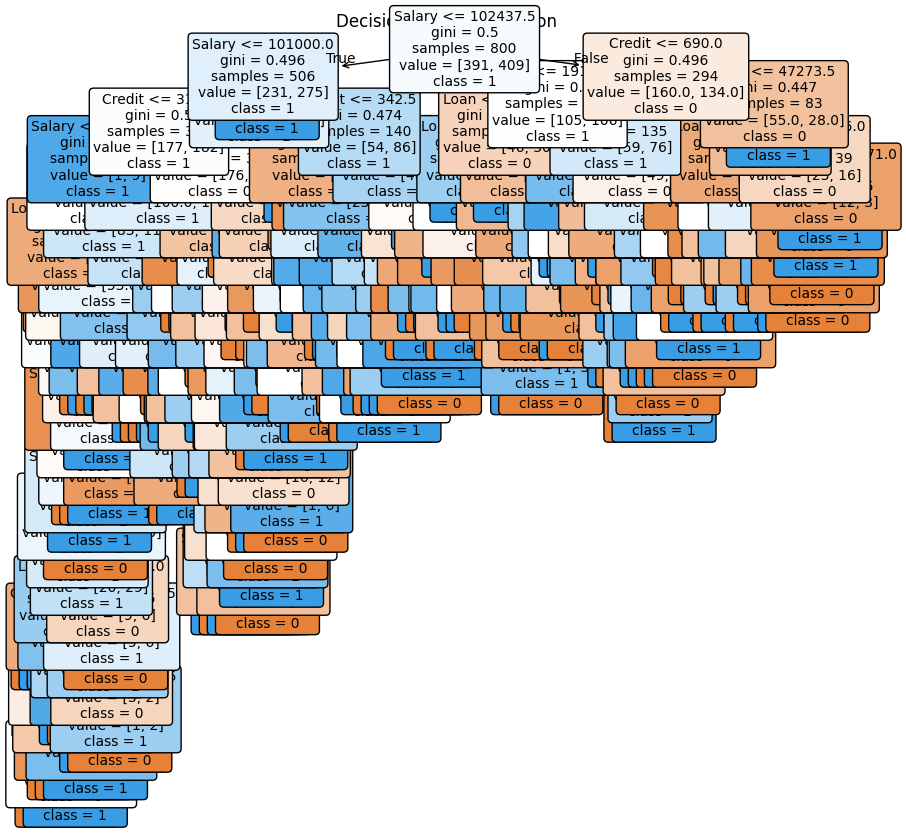

In [29]:
plt.figure(figsize=(10,10))
plot_tree(model,feature_names=dfl.columns.tolist(),class_names=['0','1'],rounded=True,filled=True,fontsize=10)
plt.title('Decision Tree Visualization')
plt.show()

In [30]:
model=Ridge(alpha=1.0)
alpha=[0.25,1.0,0.78]
model_new=GridSearchCV(model,param_grid={'alpha':alpha})
model_new.fit(x_train,y_train)

GridSearchCV(estimator=Ridge(), param_grid={'alpha': [0.25, 1.0, 0.78]})

In [31]:
model=Lasso(alpha=1.0)
alpha=[0.25,1.0,0.78]
model_new=GridSearchCV(model,param_grid={'alpha':alpha})
model_new.fit(x_train,y_train)

GridSearchCV(estimator=Lasso(), param_grid={'alpha': [0.25, 1.0, 0.78]})

In [32]:
print(model_new.best_params_)
print(model_new.best_score_)

{'alpha': 1.0}
-0.002068536226662343


In [33]:
model=DecisionTreeClassifier()
model.fit(x_train,y_train)

DecisionTreeClassifier()

In [34]:
model=DecisionTreeClassifier()
model.fit(x_train,y_train)
acc_full=model.score(x_train,y_train)
acc_test=model.score(x_test,y_test)
print('full tree accuracy:',{acc_full})
print('test tree depth:',model.get_depth())
print('test tree leaves:',model.get_n_leaves())

full tree accuracy: {1.0}
test tree depth: 27
test tree leaves: 228


In [35]:
path=model.cost_complexity_pruning_path(x_train,y_train)
ccp_alphas=path.ccp_alphas
path

{'ccp_alphas': array([0.        , 0.00104167, 0.00104167, 0.00107143, 0.00107143,
        0.00109375, 0.00111111, 0.001125  , 0.001125  , 0.001125  ,
        0.001125  , 0.00113636, 0.00113636, 0.00113636, 0.00113636,
        0.00115385, 0.00115385, 0.00115385, 0.00117647, 0.00117647,
        0.00125   , 0.00131579, 0.00140909, 0.00142857, 0.00144444,
        0.0014881 , 0.0015    , 0.0015    , 0.00151154, 0.00160714,
        0.00166667, 0.00166667, 0.00166667, 0.00166667, 0.00166667,
        0.00166667, 0.00166667, 0.00169922, 0.00171429, 0.00171429,
        0.00184615, 0.001875  , 0.001875  , 0.001875  , 0.001875  ,
        0.00189394, 0.00190909, 0.00192402, 0.002     , 0.002     ,
        0.002     , 0.002     , 0.002     , 0.002     , 0.002     ,
        0.002     , 0.00201681, 0.00202564, 0.00202953, 0.00208333,
        0.00208333, 0.00208333, 0.00213696, 0.00214286, 0.00214286,
        0.00214286, 0.00214286, 0.00221212, 0.00222222, 0.00222222,
        0.00222222, 0.00222222, 0.

In [36]:
 accuracy_score(y_test,y_pred)
 confusion_matrix(y_test,y_pred)
 #recall_score(y_test,y_pred)
 #precision_score(y_test,y_pred)

array([[42, 59],
       [39, 60]])

In [37]:
poly=PolynomialFeatures(degree=2)
x_poly=poly.fit_transform(x)
poly


PolynomialFeatures()

In [38]:
model= LinearRegression()
model.fit(x_poly,y)


LinearRegression()

In [39]:
 y_pred=model.predict(x_poly)
 y_pred

array([0.42496097, 0.56692651, 0.46473901, 0.52775898, 0.52458476,
       0.75622742, 0.5020063 , 0.4701034 , 0.4365544 , 0.54250278,
       0.62714824, 0.6189927 , 0.48218062, 0.46069525, 0.53113385,
       0.51966675, 0.44171154, 0.49724804, 0.5183491 , 0.37367585,
       0.51520941, 0.46407444, 0.40174983, 0.42886003, 0.45461419,
       0.45447357, 0.55091646, 0.47130868, 0.57320055, 0.51763737,
       0.49778736, 0.55918583, 0.67958805, 0.43918511, 0.46393929,
       0.79296353, 0.63945183, 0.43637482, 0.53136239, 0.51682556,
       0.48030525, 0.35390213, 0.52388077, 0.43129023, 0.55852681,
       0.52208658, 0.55272695, 0.43471496, 0.49140134, 0.64436712,
       0.45474237, 0.51243511, 0.5813225 , 0.54081158, 0.58183837,
       0.50310221, 0.65296562, 0.63134505, 0.52926573, 0.45825735,
       0.49485231, 0.44876438, 0.52775579, 0.53920612, 0.46831485,
       0.45195513, 0.52239991, 0.51154098, 0.44907478, 0.50557845,
       0.52755787, 0.65824739, 0.49784701, 0.56558845, 0.50644

In [40]:
 x=dfl.iloc[:,:-1]
 y=dfl.iloc[:,-1]
 kf=KFold(n_splits=5,shuffle=True,random_state=42)
 ac=0
 for train_index,test_index in kf.split(x):
     x_train,x_test=x.iloc[train_index],x.iloc[test_index]
     y_train,y_test=y.iloc[train_index],y.iloc[test_index]
     model=LogisticRegression()
     model.fit(x_train,y_train)
     y_pred=model.predict(x_test)
     accuracy=accuracy_score(y_test,y_pred)
     if ac<accuracy:
         ac=accuracy

     print(ac)




0.535
0.535
0.535
0.555
0.555


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

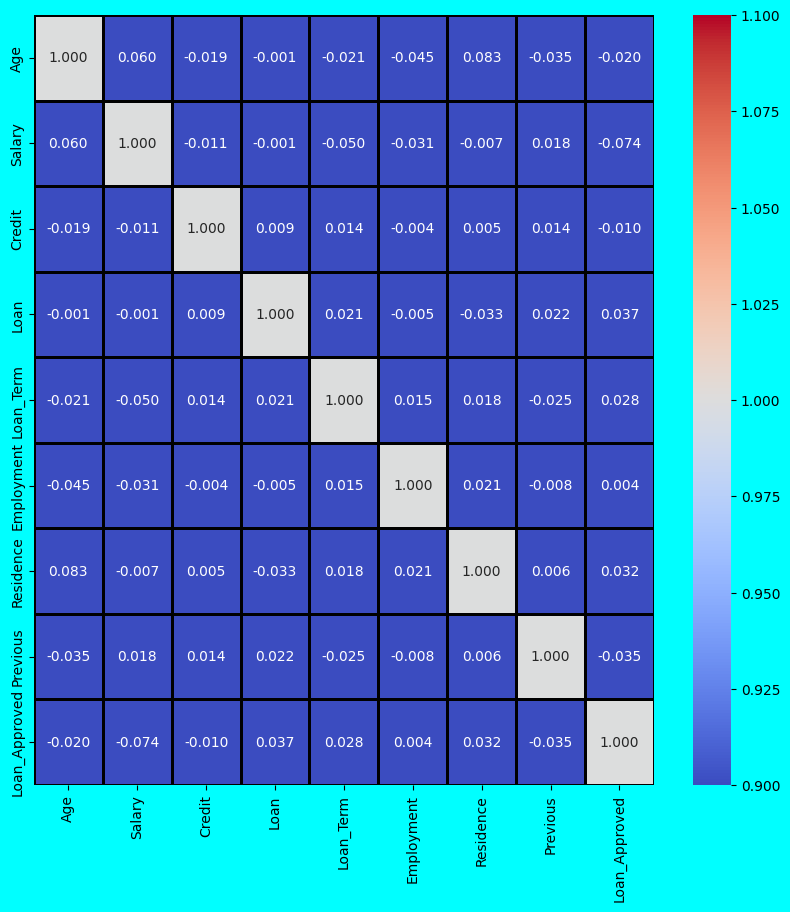

In [41]:
plt.figure(facecolor='cyan',figsize=(10,10))
c_var=dfl.corr(numeric_only=True)
sns.heatmap(c_var,annot=True,linewidths=2,linecolor='black',vmin=1.0,vmax=1.0,cmap='coolwarm',fmt='0.3f')
plt.show()

/tmp/ipykernel_399/4163944655.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(y='Credit' ,data=dfl,palette='rainbow')


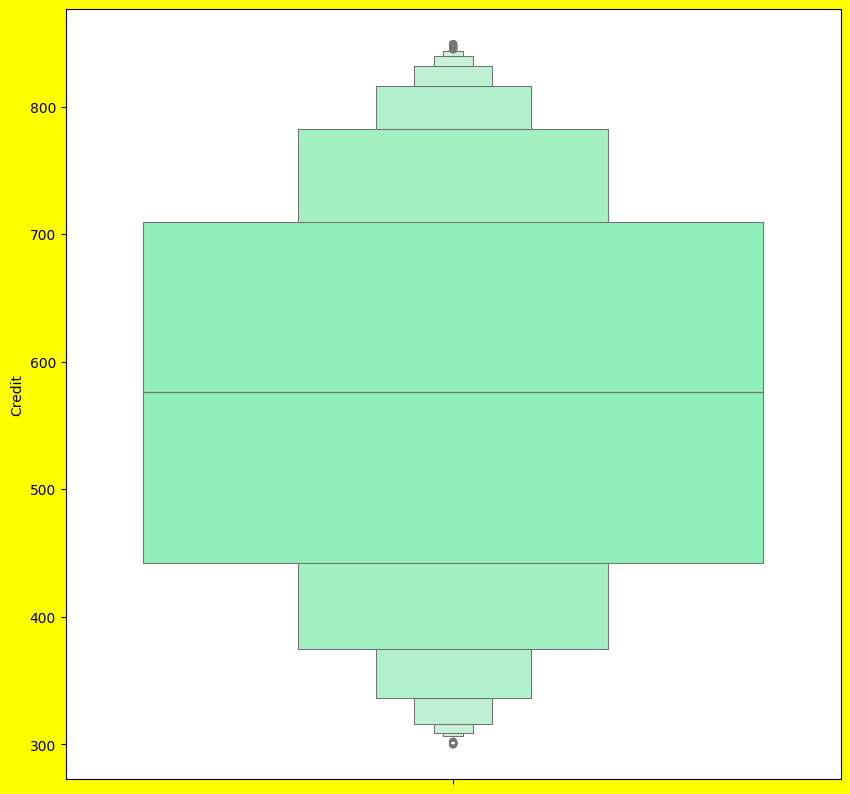

In [42]:
plt.figure(facecolor='yellow',figsize=(10,10))
sns.boxenplot(y='Credit' ,data=dfl,palette='rainbow')
plt.show()

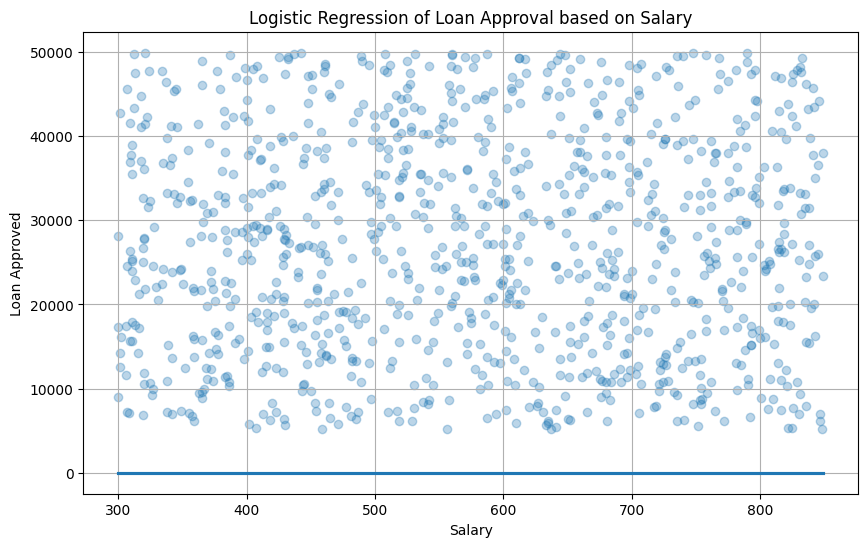

In [43]:
plt.figure(figsize=(10, 6))
sns.regplot(x='Credit', y='Loan', data=dfl, logistic=True, scatter_kws={'alpha':0.3})
plt.title('Logistic Regression of Loan Approval based on Salary')
plt.xlabel('Salary')
plt.ylabel('Loan Approved')
plt.grid(True)
plt.show()

In [44]:
dfl=dfl.rename(columns={'Residence_Type':'Residence','Employment_Status':'Employment','Previous_Default':'Previous','Credit_Score':'Credit','Loan_Amount':'Loan'})
dfl

,Age,Salary,Credit,Loan,Loan_Term,Employment,Residence,Previous,Loan_Approved
0,56,136748,584,38209,2,0,1,1,1
1,46,25287,815,27424,1,1,2,0,1
2,32,146593,398,42396,0,2,2,1,1
3,60,54387,696,11370,1,2,1,0,0
4,25,28512,788,14528,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...
995,22,49241,500,41020,1,1,1,0,1
996,40,116214,423,12415,3,1,1,0,1
997,27,64569,300,28155,2,1,2,1,1
998,61,31745,490,48884,0,1,0,0,1


In [45]:
x=np.array([[1],[2],[3],[5],[6]])
y=np.array([2,3,2.5,5,4.5])


In [46]:

knn_reg_model=KNeighborsRegressor(n_neighbors=3)
knn_reg_model.fit(x,y)

KNeighborsRegressor(n_neighbors=3)

In [47]:
dfl.isnull().sum()

,0
Age,0
Salary,0
Credit,0
Loan,0
Loan_Term,0
Employment,0
Residence,0
Previous,0
Loan_Approved,0


In [48]:
x=dfl.iloc[:,:-1]
y=dfl.iloc[:,-1]
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [49]:
x_test

,Age,Salary,Credit,Loan,Loan_Term,Employment,Residence,Previous
521,25,48769,586,29322,2,1,0,0
737,38,109431,311,25447,0,2,0,0
740,34,128730,717,34336,1,1,2,1
660,38,60998,821,10355,1,0,2,0
411,61,98757,680,31421,0,2,2,0
...,...,...,...,...,...,...,...,...
408,54,136243,448,43975,2,2,0,0
332,34,146944,719,47138,0,0,0,1
208,40,21645,319,6875,2,2,2,1
613,22,90342,734,42291,2,2,0,1


In [50]:
x_test,x_train,y_test,y_train

(     Age  Salary  Credit   Loan  Loan_Term  Employment  Residence  Previous
 521   25   48769     586  29322          2           1          0         0
 737   38  109431     311  25447          0           2          0         0
 740   34  128730     717  34336          1           1          2         1
 660   38   60998     821  10355          1           0          2         0
 411   61   98757     680  31421          0           2          2         0
 ..   ...     ...     ...    ...        ...         ...        ...       ...
 408   54  136243     448  43975          2           2          0         0
 332   34  146944     719  47138          0           0          0         1
 208   40   21645     319   6875          2           2          2         1
 613   22   90342     734  42291          2           2          0         1
 78    40   54016     415  14885          3           0          1         0
 
 [200 rows x 8 columns],
      Age  Salary  Credit   Loan  Loan_Term  Empl

In [51]:
model=KNeighborsClassifier(n_neighbors=3)
model.fit(x_train,y_train)


KNeighborsClassifier(n_neighbors=3)

In [52]:
y_pred=model.predict(x_test)
y_pred

array([0, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0,
       1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0,
       1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1,
       1, 1])

In [53]:
dfl.head()

,Age,Salary,Credit,Loan,Loan_Term,Employment,Residence,Previous,Loan_Approved
0,56,136748,584,38209,2,0,1,1,1
1,46,25287,815,27424,1,1,2,0,1
2,32,146593,398,42396,0,2,2,1,1
3,60,54387,696,11370,1,2,1,0,0
4,25,28512,788,14528,0,0,1,0,0


In [54]:
x=dfl[['Age']]
y=dfl['Loan_Approved']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
model=RandomForestClassifier(n_estimators=100,max_features='sqrt',max_depth=2,bootstrap=True,oob_score=True,random_state=42)
model.fit(x_train,y_train)

RandomForestClassifier(max_depth=2, oob_score=True, random_state=42)

In [55]:
y_pred=model.predict(x_test)
y_pred

accuracy_score(y_test,y_pred)

0.445

In [56]:
model=BaggingClassifier(estimator=LogisticRegression(),n_estimators=10,random_state=42)
model.fit(x_train,y_train)

BaggingClassifier(estimator=LogisticRegression(), random_state=42)

In [57]:
model=AdaBoostClassifier(estimator=DecisionTreeClassifier(),n_estimators=50,learning_rate=0.2,random_state=42)
model.fit(x_train,y_train)

AdaBoostClassifier(estimator=DecisionTreeClassifier(), learning_rate=0.2,
                   random_state=42)

In [58]:
y_pred=model.predict(x_test)
y_pred

array([1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0,
       0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0,
       1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0,
       1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1,
       1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1,
       0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0,
       1, 0])

In [59]:
r2_score(y_test,y_pred)

-0.9448621553884715

In [60]:
from sklearn.ensemble import StackingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB,MultinomialNB,GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

model=[('KNN',KNeighborsClassifier()),('SVCC',SVC()),('BN',BernoulliNB()),('MNB',MultinomialNB()),('GNB',GaussianNB()),('DT',DecisionTreeClassifier())]

model=StackingClassifier(estimators=model,final_estimator=LogisticRegression(),cv=5)

model.fit(x_train,y_train)

StackingClassifier(cv=5,
                   estimators=[('KNN', KNeighborsClassifier()), ('SVCC', SVC()),
                               ('BN', BernoulliNB()), ('MNB', MultinomialNB()),
                               ('GNB', GaussianNB()),
                               ('DT', DecisionTreeClassifier())],
                   final_estimator=LogisticRegression())

In [61]:
y_pred=model.predict(x_test)
y_pred

array([1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0,
       0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1,
       1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1,
       1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0,
       0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0,
       1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1,
       1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1,
       1, 1])

In [62]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split

# Redefine x and y to ensure correct classification target
x = dfl.drop('Loan_Approved', axis=1)
y = dfl['Loan_Approved']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

xggb = XGBClassifier(n_estimators=10, learning_rate=0.1, max_depth=3, random_state=42)
xggb.fit(x_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=10,
              n_jobs=None, num_parallel_tree=None, ...)

/usr/local/lib/python3.13/dist-packages/xgboost/plotting.py:268: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` instead. 
  warnings.warn(


<Figure size 1000x1000 with 0 Axes>

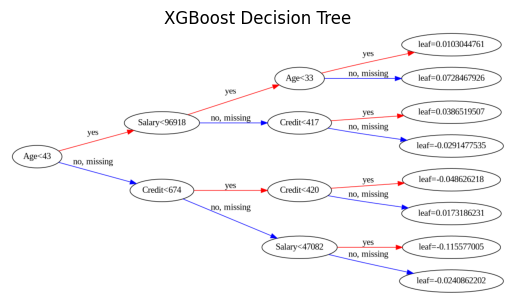

In [63]:
from xgboost import XGBClassifier, plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))
plot_tree(xggb, num_trees=0, rankdir='LR') # num_trees=0 plots the first tree
plt.title('XGBoost Decision Tree')
plt.show()

In [64]:
x=dfl.iloc[:,:-1]
y=dfl.iloc[:,-1]
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [65]:
model = DecisionTreeClassifier(random_state=42)
model.fit(x_train, y_train)

DecisionTreeClassifier(random_state=42)

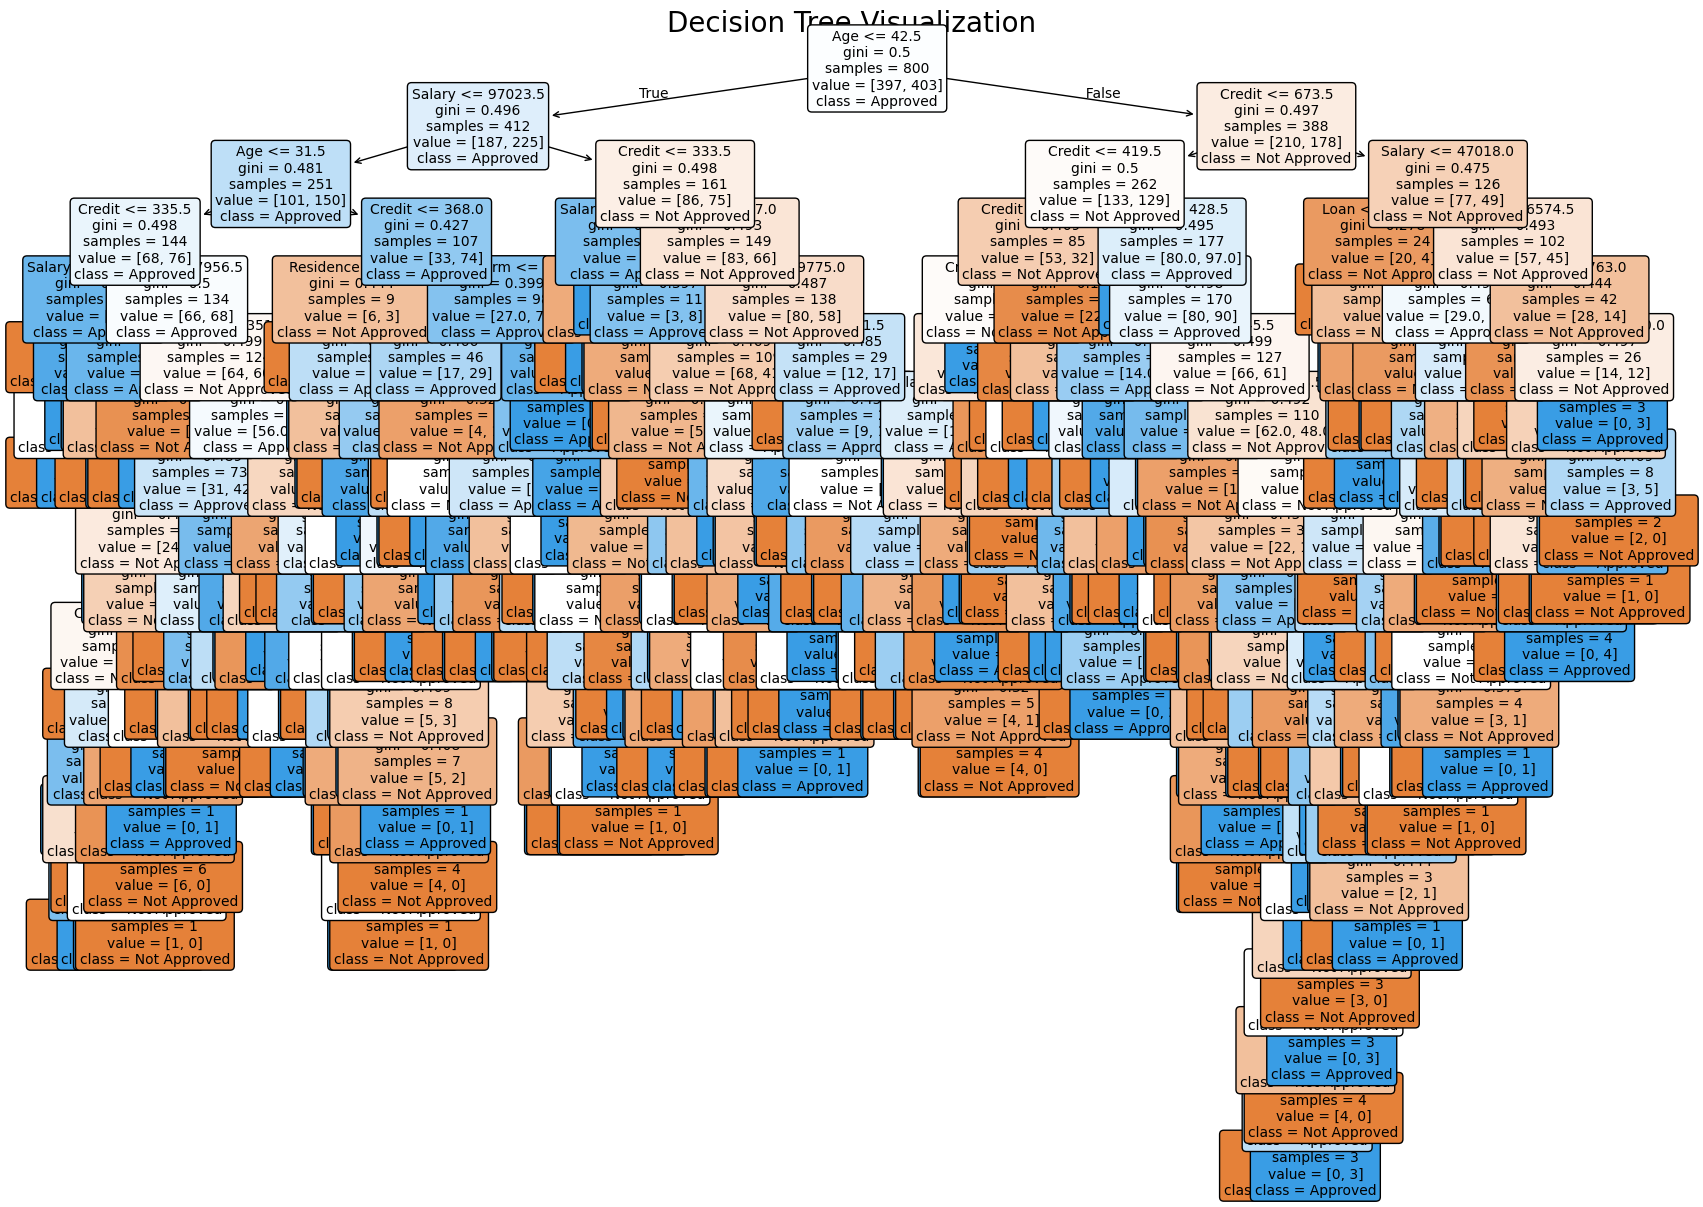

In [66]:
from sklearn.tree import plot_tree as sk_plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 15)) # Increased figure size for better readability
sk_plot_tree(model, feature_names=x.columns.tolist(), class_names=['Not Approved', 'Approved'], filled=True, rounded=True, fontsize=10)
plt.title('Decision Tree Visualization', fontsize=20)
plt.show()

In [67]:
x_train,x_test,y_train,y_test

(     Age  Salary  Credit   Loan  Loan_Term  Employment  Residence  Previous
 29    44   85441     507  17109          1           1          2         0
 535   38   87298     489  10776          2           0          0         0
 695   45   49629     762  39441          2           0          0         0
 557   47   75337     809  40596          0           0          0         1
 836   46  101121     504  31956          2           2          0         0
 ..   ...     ...     ...    ...        ...         ...        ...       ...
 106   52  118723     689  31649          2           0          2         0
 270   26  135654     388  22514          3           1          0         1
 860   64  135005     683   8642          2           2          2         0
 435   26   47856     841  45697          2           2          0         0
 102   28   79379     306  11581          1           1          0         0
 
 [800 rows x 8 columns],
      Age  Salary  Credit   Loan  Loan_Term  Empl

In [68]:
model=KNeighborsClassifier(n_neighbors=3)
model.fit(x_train,y_train)

KNeighborsClassifier(n_neighbors=3)

In [69]:
model=BaggingClassifier(estimator=LogisticRegression(),n_estimators=10,random_state=42)
model.fit(x_train,y_train)

model=AdaBoostClassifier(estimator=DecisionTreeClassifier(),n_estimators=50,learning_rate=0.2,random_state=42)
model.fit(x_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

AdaBoostClassifier(estimator=DecisionTreeClassifier(), learning_rate=0.2,
                   random_state=42)

/tmp/ipykernel_399/1898441393.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(x='Age',data=dfl,bins=5,color='black',multiple='dodge',palette='rainbow',shrink=0.9)


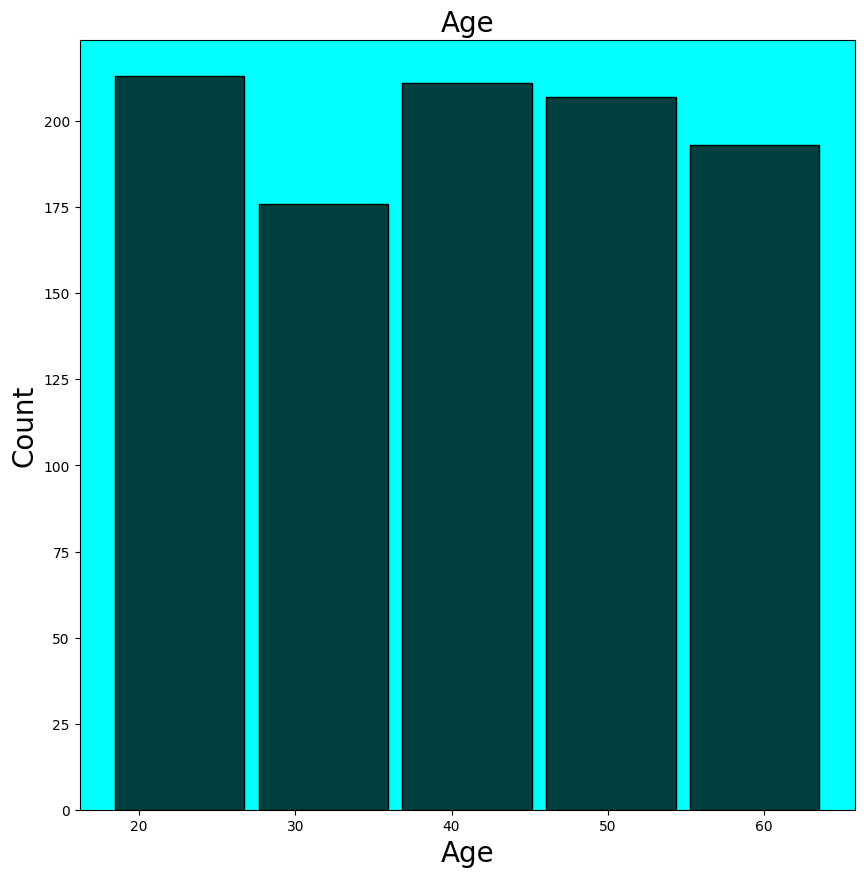

In [70]:
plt.figure(figsize=(10,10))
sns.histplot(x='Age',data=dfl,bins=5,color='black',multiple='dodge',palette='rainbow',shrink=0.9)
plt.xlabel('Age',fontsize=20)
plt.ylabel('Count',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age',fontsize=20,y=1)
for i in hist.containers:
    hist.bar_label(i,color='black',rotation=45,fontsize=10,label_type='edge')

plt.show()

In [71]:
model=DecisionTreeClassifier()
model.fit(x_train,y_train)

DecisionTreeClassifier()

In [72]:
y_pred=model.predict(x_test)
y_pred

array([0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1,
       0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0,
       0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1,
       0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1,
       1, 0])

In [73]:
dfl.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Age            1000 non-null   int64
 1   Salary         1000 non-null   int64
 2   Credit         1000 non-null   int64
 3   Loan           1000 non-null   int64
 4   Loan_Term      1000 non-null   int64
 5   Employment     1000 non-null   int64
 6   Residence      1000 non-null   int64
 7   Previous       1000 non-null   int64
 8   Loan_Approved  1000 non-null   int64
dtypes: int64(9)
memory usage: 70.4 KB


In [74]:
dfl.isnull().sum()

,0
Age,0
Salary,0
Credit,0
Loan,0
Loan_Term,0
Employment,0
Residence,0
Previous,0
Loan_Approved,0


In [75]:
model=Lasso(alpha=1.0)
alpha=[0.25,1.0,0.78]
model_new=GridSearchCV(model,param_grid={'alpha':alpha})
model_new.fit(x_train,y_train)


GridSearchCV(estimator=Lasso(), param_grid={'alpha': [0.25, 1.0, 0.78]})

In [76]:
model=Ridge(alpha=1.0)
alpha=[1.0,1.0,0.78]
model_new=GridSearchCV(model,param_grid={'alpha':alpha})
model_new.fit(x_train,y_train)

GridSearchCV(estimator=Ridge(), param_grid={'alpha': [1.0, 1.0, 0.78]})

In [77]:
x_test,x_test

(     Age  Salary  Credit   Loan  Loan_Term  Employment  Residence  Previous
 521   25   48769     586  29322          2           1          0         0
 737   38  109431     311  25447          0           2          0         0
 740   34  128730     717  34336          1           1          2         1
 660   38   60998     821  10355          1           0          2         0
 411   61   98757     680  31421          0           2          2         0
 ..   ...     ...     ...    ...        ...         ...        ...       ...
 408   54  136243     448  43975          2           2          0         0
 332   34  146944     719  47138          0           0          0         1
 208   40   21645     319   6875          2           2          2         1
 613   22   90342     734  42291          2           2          0         1
 78    40   54016     415  14885          3           0          1         0
 
 [200 rows x 8 columns],
      Age  Salary  Credit   Loan  Loan_Term  Empl

In [78]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
x=dfl.drop('Loan_Approved',axis=1)
y=dfl['Loan_Approved']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

xggb = XGBClassifier(n_estimators=10, learning_rate=0.1, max_depth=3, random_state=42)
xggb.fit(x_train, y_train)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=10,
              n_jobs=None, num_parallel_tree=None, ...)

In [79]:
model=LogisticRegression()
model.fit(x_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [80]:
dfl.head()

,Age,Salary,Credit,Loan,Loan_Term,Employment,Residence,Previous,Loan_Approved
0,56,136748,584,38209,2,0,1,1,1
1,46,25287,815,27424,1,1,2,0,1
2,32,146593,398,42396,0,2,2,1,1
3,60,54387,696,11370,1,2,1,0,0
4,25,28512,788,14528,0,0,1,0,0


In [81]:
dfl.duplicated().sum()

np.int64(0)

In [82]:
dfl.head()

,Age,Salary,Credit,Loan,Loan_Term,Employment,Residence,Previous,Loan_Approved
0,56,136748,584,38209,2,0,1,1,1
1,46,25287,815,27424,1,1,2,0,1
2,32,146593,398,42396,0,2,2,1,1
3,60,54387,696,11370,1,2,1,0,0
4,25,28512,788,14528,0,0,1,0,0


In [83]:
dfl.rename(columns={'Residence_Type':'Residence','Employment_Status':'Employment','Previous_Default':'Previous','Credit_Score':'Credit','Loan_Amount':'Loan'},inplace=True)
dfl

,Age,Salary,Credit,Loan,Loan_Term,Employment,Residence,Previous,Loan_Approved
0,56,136748,584,38209,2,0,1,1,1
1,46,25287,815,27424,1,1,2,0,1
2,32,146593,398,42396,0,2,2,1,1
3,60,54387,696,11370,1,2,1,0,0
4,25,28512,788,14528,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...
995,22,49241,500,41020,1,1,1,0,1
996,40,116214,423,12415,3,1,1,0,1
997,27,64569,300,28155,2,1,2,1,1
998,61,31745,490,48884,0,1,0,0,1


/tmp/ipykernel_399/926234948.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(x='Age',data=dfl,bins=5,color='black',multiple='dodge',palette='rainbow',shrink=0.9)


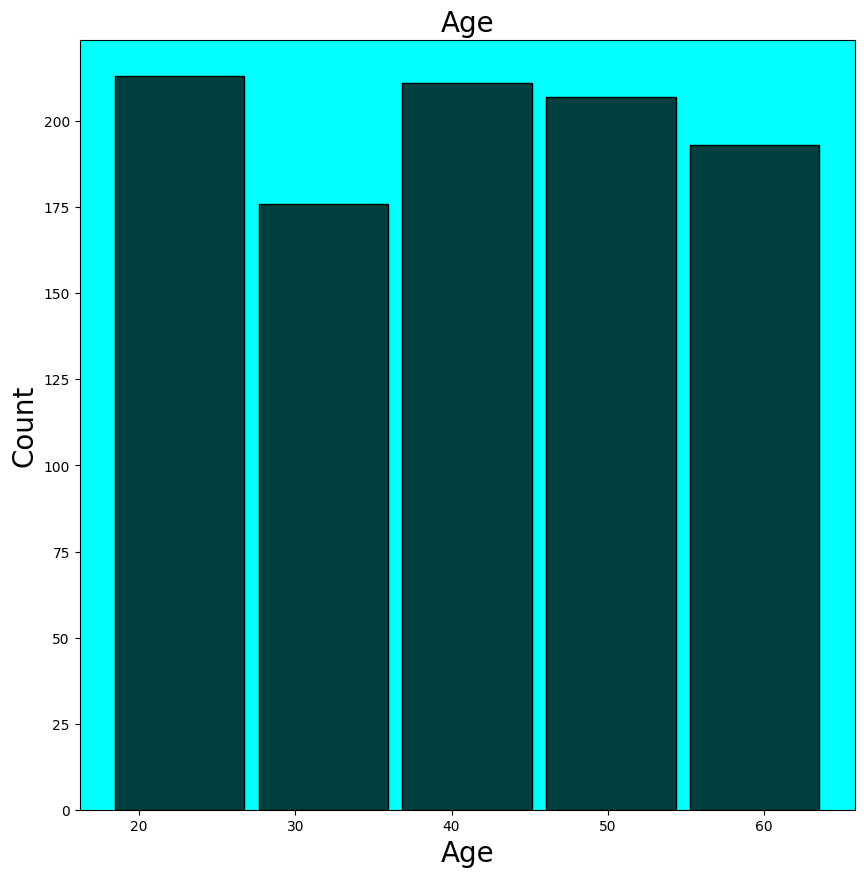

In [84]:
plt.figure(figsize=(10,10))
sns.histplot(x='Age',data=dfl,bins=5,color='black',multiple='dodge',palette='rainbow',shrink=0.9)
plt.xlabel('Age',fontsize=20)
plt.ylabel('Count',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age',fontsize=20,y=1)
for i in hist.containers:
    hist.bar_label(i,color='black',rotation=45,fontsize=10,label_type='edge')

plt.show()


In [85]:
x=dfl.iloc[:,2:4]
y=dfl.iloc[:,-1]
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
sc=StandardScaler()
x_train=sc.fit_transform(x_train)
x_test=sc.transform(x_test)
from sklearn.svm import SVC
classifier=SVC(kernel='linear',random_state=0)
classifier.fit(x_train,y_train)
y_pred=classifier.predict(x_test)
y_pred
accuracy_score(y_test,y_pred)

0.495

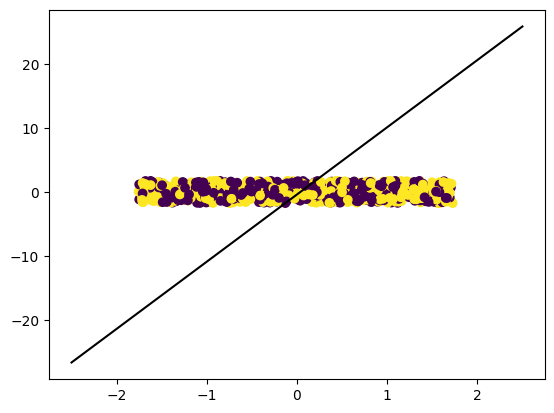

In [86]:
x=dfl.iloc[:,2:4]
y=dfl.iloc[:,-1]
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
sc=StandardScaler()
x_train=sc.fit_transform(x_train)
x_test=sc.transform(x_test)
from sklearn.svm import SVC
classifier=SVC(kernel='linear',random_state=0)
classifier.fit(x_train,y_train)
y_pred=classifier.predict(x_test)
y_pred
accuracy_score(y_test,y_pred)
w=classifier.coef_[0]
b=classifier.intercept_[0]
xx=np.linspace(-2.5,2.5)
yy=-b/w[1]-w[0]/w[1]*xx
plt.scatter(x_train[:,0],x_train[:,1],c=y_train)
plt.plot(xx,yy,'k-')
plt.show()

In [87]:
model=StandardScaler
classifier=StandardScaler()
classifier.fit(x_train,y_train)

StandardScaler()

In [88]:
from sklearn.svm import SVC
classifier=SVC(kernel='poly',degree=3,random_state=0)
classifier.fit(x_train,y_train)
y_pred=classifier.predict(x_test)
y_pred
accuracy_score(y_test,y_pred)

0.505

In [89]:
  from sklearn.svm import SVC
  classifier=SVC(kernel='rbf',random_state=0)
  classifier.fit(x_train,y_train)
  y_pred=classifier.predict(x_test)
  y_pred
  accuracy_score(y_test,y_pred)



0.495

In [90]:
model= DecisionTreeClassifier()
model.fit(x_train,y_train)

DecisionTreeClassifier()

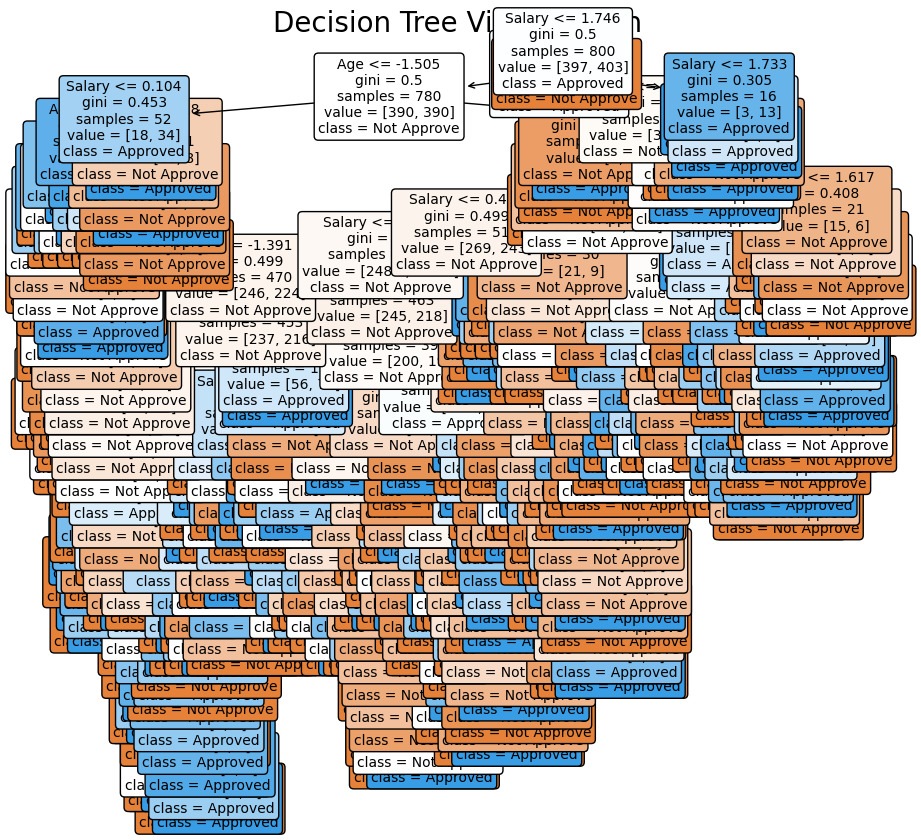

In [91]:
from sklearn.tree import plot_tree
import  matplotlib.pyplot as plt
plt.figure(figsize=(10,10))
#sk_plot_tree(model, feature_names=x.columns.tolist(), class_names=['Not Approved', 'Approved'], filled=True, rounded=True, fontsize=10)
plot_tree(model,feature_names=dfl.columns.tolist(),class_names=['Not Approve','Approved'],rounded=True,filled=True,fontsize=10)
plt.title('Decision Tree Visualization', fontsize=20)
plt.show()


In [92]:
dfl.head()

,Age,Salary,Credit,Loan,Loan_Term,Employment,Residence,Previous,Loan_Approved
0,56,136748,584,38209,2,0,1,1,1
1,46,25287,815,27424,1,1,2,0,1
2,32,146593,398,42396,0,2,2,1,1
3,60,54387,696,11370,1,2,1,0,0
4,25,28512,788,14528,0,0,1,0,0


In [93]:
dfl.tail()

,Age,Salary,Credit,Loan,Loan_Term,Employment,Residence,Previous,Loan_Approved
995,22,49241,500,41020,1,1,1,0,1
996,40,116214,423,12415,3,1,1,0,1
997,27,64569,300,28155,2,1,2,1,1
998,61,31745,490,48884,0,1,0,0,1
999,19,46029,815,21964,1,0,0,1,0


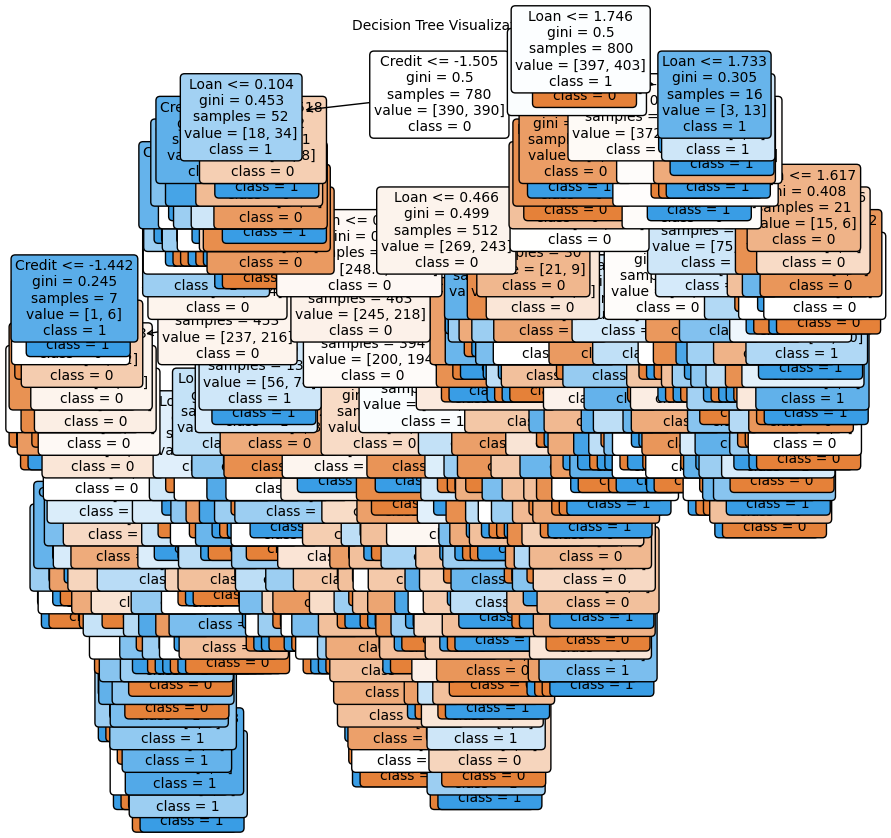

In [94]:
model = DecisionTreeClassifier()
model.fit(x_train, y_train)
plt.figure(figsize=(10,10))
plot_tree(model,feature_names=['Credit','Loan'],class_names=['0','1'],rounded=True,filled=True,fontsize=10)
plt.title('Decision Tree Visualization',fontsize=10)
plt.show()



In [95]:
from sklearn.preprocessing import LabelEncoder
dfl_encoded=dfl.apply(LabelEncoder().fit_transform)
# Select only naturally categorical features for CategoricalNB
x=dfl_encoded[['Loan_Term','Employment','Residence','Previous']]
y=dfl_encoded.iloc[:,-1]
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
from sklearn.naive_bayes import CategoricalNB
model=CategoricalNB(alpha=1.0,fit_prior=True)
model.fit(x_train,y_train)

y_pred=model.predict(x_test)
y_pred
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.44

In [96]:
dfl.isnull().sum()

,0
Age,0
Salary,0
Credit,0
Loan,0
Loan_Term,0
Employment,0
Residence,0
Previous,0
Loan_Approved,0


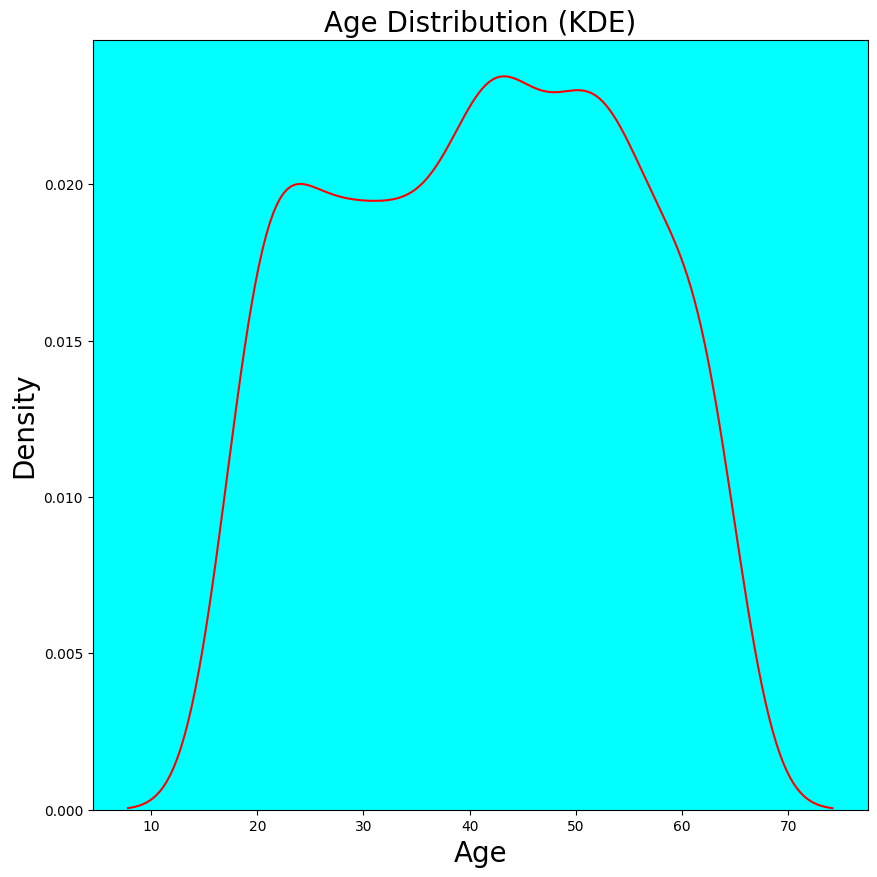

In [97]:

plt.figure(figsize=(10,10))
sns.kdeplot(x='Age',data=dfl,color='red')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Density',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age Distribution (KDE)',fontsize=20,y=1)
plt.show()

In [98]:
model=DecisionTreeClassifier()
model.fit(x_train,y_train)

DecisionTreeClassifier()

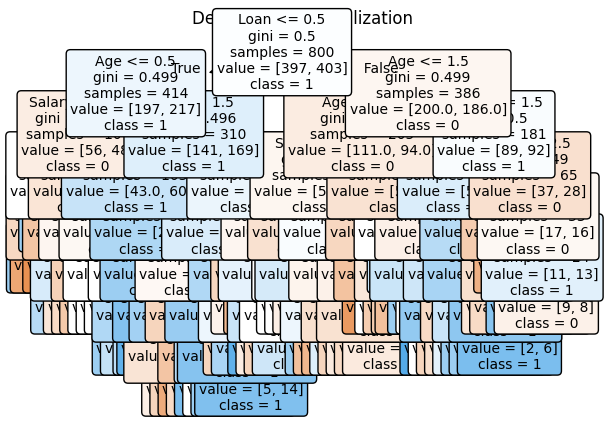

In [99]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plot_tree(model,feature_names=dfl.columns.tolist(),class_names=['0','1'],rounded=True,filled=True,fontsize=10)
plt.title('Decision Tree Visualization')
plt.show()

In [100]:
y_pred=model.predict(x_test)
y_pred

array([1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 1, 1,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1,
       0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0,
       1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1,
       0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1,
       0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1,
       0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0,
       0, 1])

In [101]:
accuracy_score(y_test,y_pred)

0.47

In [102]:
r2_score(y_test,y_pred)

-1.1253132832080204

In [103]:
r2_score(y_test,y_pred)

-1.1253132832080204

In [104]:
accuracy_score(y_test,y_pred)

0.47

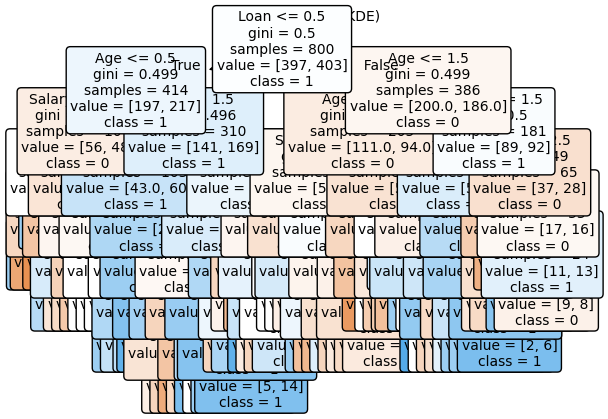

In [105]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plot_tree(model,feature_names=dfl.columns.tolist(),class_names=['0','1'],rounded=True,filled=True,fontsize=10)
plt.xlabel('Age',fontsize=20)
plt.ylabel('Density',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age Distribution (KDE)',fontsize=10,y=1)
plt.show()

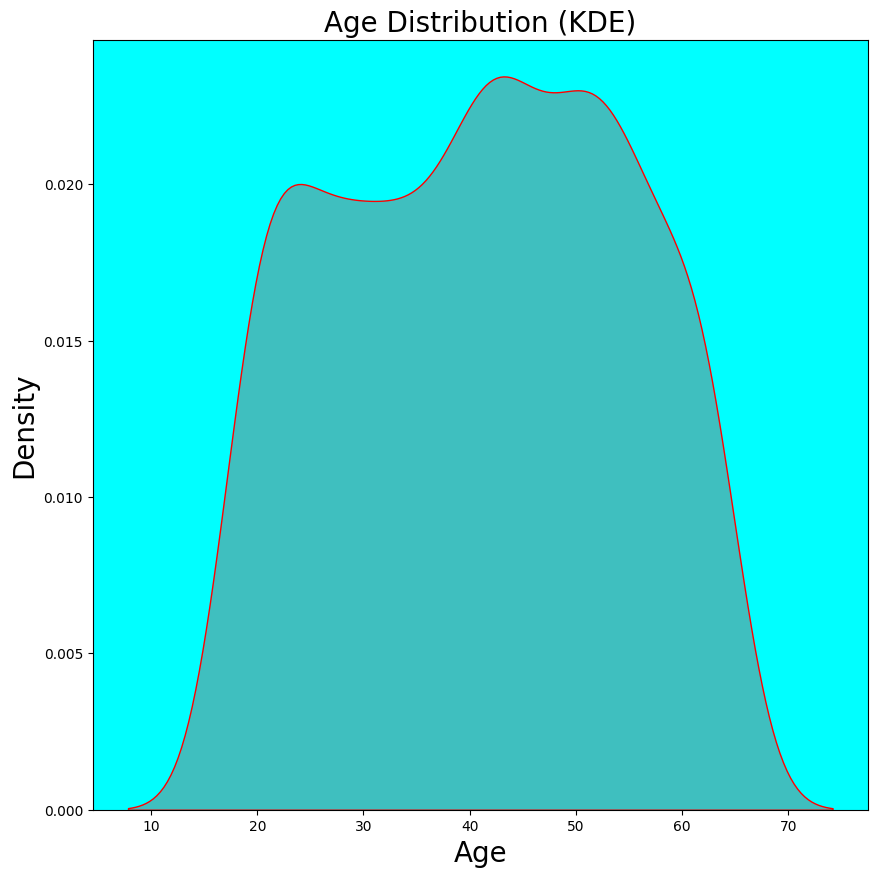

In [106]:
plt.figure(figsize=(10,10))
sns.kdeplot(x='Age',data=dfl,color='red',fill=True)
plt.xlabel('Age',fontsize=20)
plt.ylabel('Density',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age Distribution (KDE)',fontsize=20,y=1)
plt.show()

In [107]:
model=Ridge(alpha=1.0)
alpha=[0.25,1.0,0.78]
model_new=GridSearchCV(model,param_grid={'alpha':alpha})
model_new.fit(x_train,y_train)

GridSearchCV(estimator=Ridge(), param_grid={'alpha': [0.25, 1.0, 0.78]})

In [108]:
model=LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [109]:
r2_score(y_test,y_pred)

-1.1253132832080204

In [110]:
y_pred=model.predict(x_test)
y_pred

array([0.51431285, 0.47502475, 0.49395627, 0.54133154, 0.512559  ,
       0.49787602, 0.55576686, 0.48719606, 0.48719606, 0.43982079,
       0.49162597, 0.512559  , 0.512559  , 0.49787602, 0.47126939,
       0.56844833, 0.51647876, 0.49379188, 0.5103931 , 0.46250767,
       0.43373514, 0.47502475, 0.46467357, 0.57453399, 0.49162597,
       0.53524588, 0.48353881, 0.57453399, 0.45033636, 0.48570471,
       0.55184711, 0.45250226, 0.46467357, 0.47502475, 0.49771163,
       0.45033636, 0.51647876, 0.49179036, 0.5082272 , 0.45250226,
       0.53916564, 0.51055749, 0.45033636, 0.52699432, 0.55793276,
       0.48787061, 0.5103931 , 0.53916564, 0.47502475, 0.52107306,
       0.52916023, 0.52482842, 0.5103931 , 0.57453399, 0.51055749,
       0.49179036, 0.48719606, 0.54133154, 0.45858792, 0.52715871,
       0.45858792, 0.53324437, 0.47126939, 0.46693758, 0.5082272 ,
       0.51864466, 0.51647876, 0.52715871, 0.5496812 , 0.512559  ,
       0.55793276, 0.54133154, 0.48719606, 0.50230593, 0.54968

/tmp/ipykernel_399/3077891579.py:3: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(x='Age',data=dfl,color='red',fill=True,shade=True)


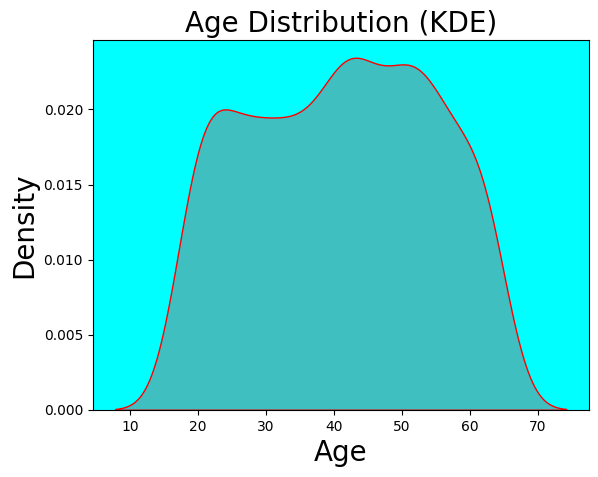

In [111]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
sns.kdeplot(x='Age',data=dfl,color='red',fill=True,shade=True)
plt.xlabel('Age',fontsize=20)
plt.ylabel('Density',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age Distribution (KDE)',fontsize=20,y=1)
plt.show()

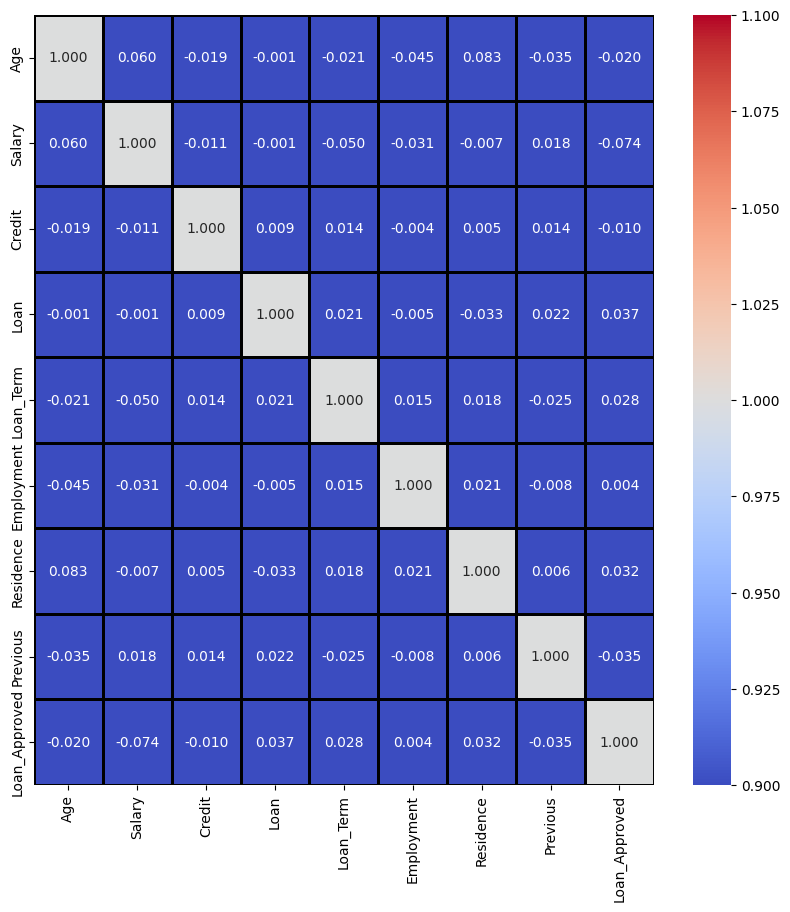

In [112]:
plt.figure(figsize=(10,10))
sns.heatmap(dfl.corr(),annot=True,linewidths=2,linecolor='black',vmin=1.0,vmax=1.0,cmap='coolwarm',fmt='0.3f')
plt.show()

Text(0.5, 1, 'Age vs Credit')

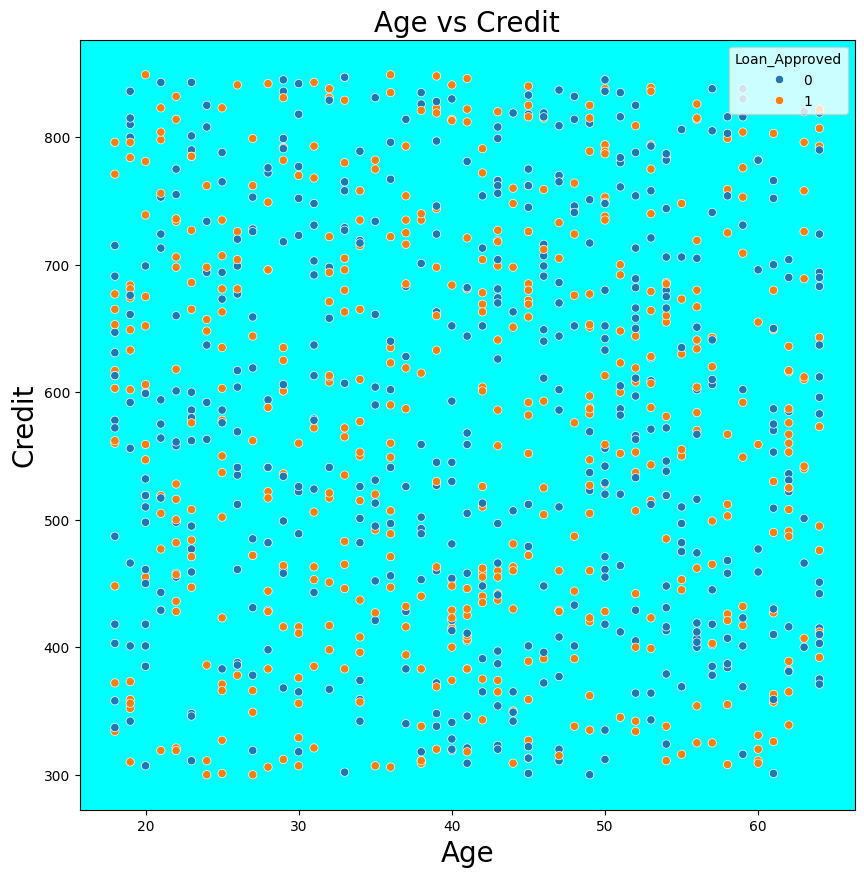

In [113]:
plt.figure(figsize=(10,10))
sns.scatterplot(x='Age',y='Credit',data=dfl,color='red',hue='Loan_Approved')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Credit',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age vs Credit',fontsize=20,y=1)

In [114]:
dfl.describe()

,Age,Salary,Credit,Loan,Loan_Term,Employment,Residence,Previous,Loan_Approved
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,40.986000,85197.154000,576.329000,27161.882000,1.453000,1.050000,0.980000,0.468000,0.508000
std,13.497852,38105.636581,157.738607,12825.343062,1.114914,0.817416,0.819922,0.499225,0.500186
min,18.000000,20060.000000,300.000000,5138.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,29.000000,52237.250000,442.000000,16181.750000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,42.000000,84850.500000,576.000000,26633.500000,1.000000,1.000000,1.000000,0.000000,1.000000
75%,52.000000,117480.000000,709.750000,38002.000000,2.000000,2.000000,2.000000,1.000000,1.000000
max,64.000000,149972.000000,849.000000,49900.000000,3.000000,2.000000,2.000000,1.000000,1.000000


/tmp/ipykernel_399/1448876998.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Age',y='Salary',data=dfl,palette='rainbow')


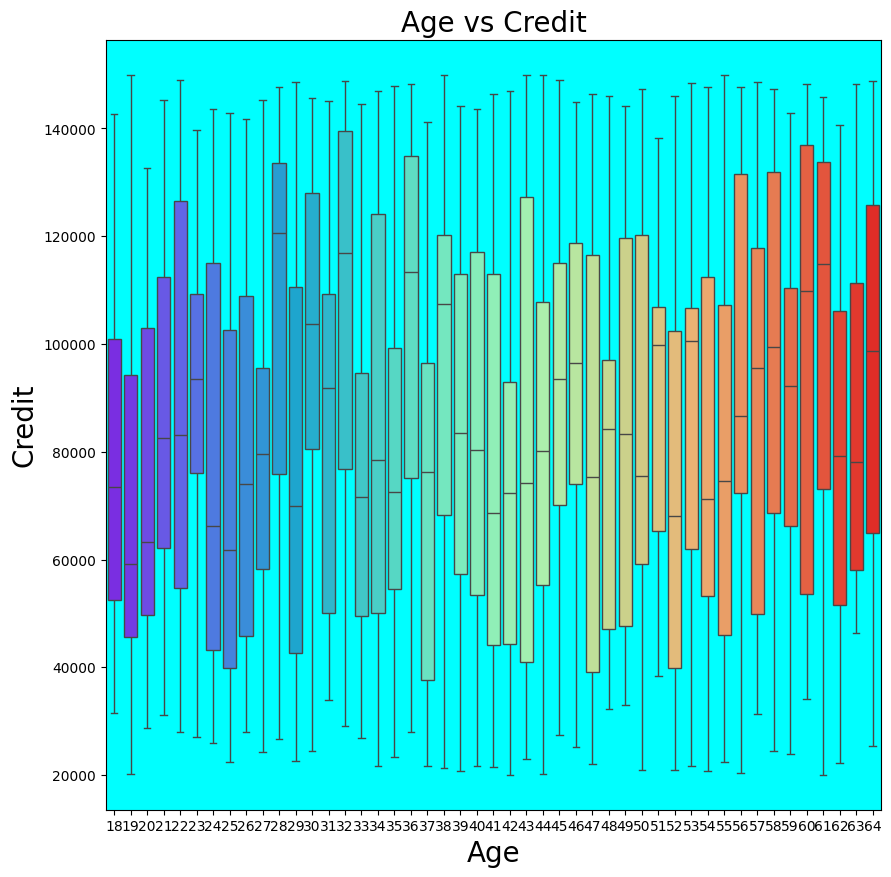

In [115]:
plt.figure(figsize=(10,10))
sns.boxplot(x='Age',y='Salary',data=dfl,palette='rainbow')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Credit',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age vs Credit',fontsize=20,y=1)
plt.show()

In [116]:
 model=DecisionTreeClassifier()
 model.fit(x_train,y_train)

DecisionTreeClassifier()

In [117]:
model=LogisticRegression()
model.fit(x_train,y_train)

LogisticRegression()

In [118]:
model=LabelEncoder()
dfl['Age']=model.fit_transform(dfl['Age'])
model=LabelEncoder()
dfl['Salary']=model.fit_transform(dfl['Salary'])
model=LabelEncoder()
dfl['Loan_Approved']=model.fit_transform(dfl['Loan_Approved'])
dfl

,Age,Salary,Credit,Loan,Loan_Term,Employment,Residence,Previous,Loan_Approved
0,38,877,584,38209,2,0,1,1,1
1,28,43,815,27424,1,1,2,0,1
2,14,963,398,42396,0,2,2,1,1
3,42,268,696,11370,1,2,1,0,0
4,7,63,788,14528,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...
995,4,226,500,41020,1,1,1,0,1
996,22,733,423,12415,3,1,1,0,1
997,9,351,300,28155,2,1,2,1,1
998,43,88,490,48884,0,1,0,0,1


In [119]:
from sklearn.ensemble import StackingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB,MultinomialNB,GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
model=[('KNN',KNeighborsClassifier()),('SVCC',SVC()),('BN',BernoulliNB()),('MNB',MultinomialNB()),('GNB',GaussianNB()),('DT',DecisionTreeClassifier())]
model=StackingClassifier(estimators=model,final_estimator=LogisticRegression(),cv=5)
model.fit(x_train,y_train)

StackingClassifier(cv=5,
                   estimators=[('KNN', KNeighborsClassifier()), ('SVCC', SVC()),
                               ('BN', BernoulliNB()), ('MNB', MultinomialNB()),
                               ('GNB', GaussianNB()),
                               ('DT', DecisionTreeClassifier())],
                   final_estimator=LogisticRegression())

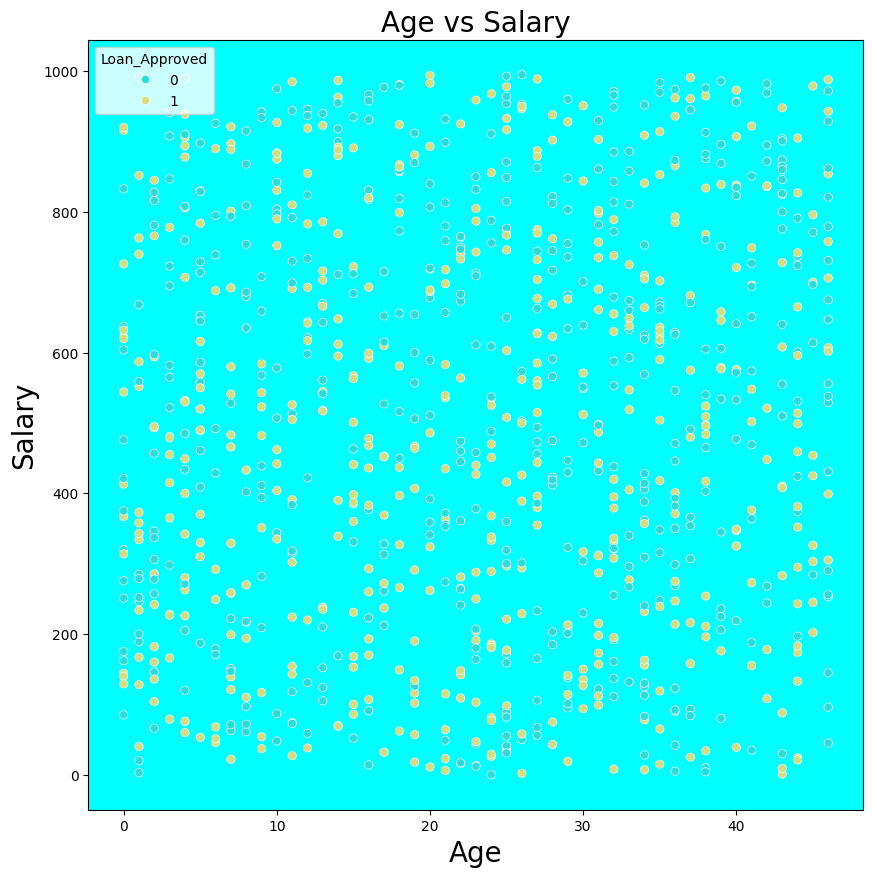

In [120]:
plt.figure(figsize=(10,10))
sns.scatterplot(x='Age',y='Salary',data=dfl,hue='Loan_Approved',palette='rainbow')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Salary',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age vs Salary',fontsize=20,y=1)
plt.show()

In [121]:
pd.read_csv('loan_approval_dataset.csv')

,Age,Salary,Credit_Score,Loan_Amount,Loan_Term,Employment_Status,Residence_Type,Previous_Default,Loan_Approved
0,56,136748,584,38209,36 months,Employed,Owned,Yes,Yes
1,46,25287,815,27424,24 months,Self-Employed,Rented,No,Yes
2,32,146593,398,42396,12 months,Unemployed,Rented,Yes,Yes
3,60,54387,696,11370,24 months,Unemployed,Owned,No,No
4,25,28512,788,14528,12 months,Employed,Owned,No,No
...,...,...,...,...,...,...,...,...,...
995,22,49241,500,41020,24 months,Self-Employed,Owned,No,Yes
996,40,116214,423,12415,48 months,Self-Employed,Owned,No,Yes
997,27,64569,300,28155,36 months,Self-Employed,Rented,Yes,Yes
998,61,31745,490,48884,12 months,Self-Employed,Mortgage,No,Yes


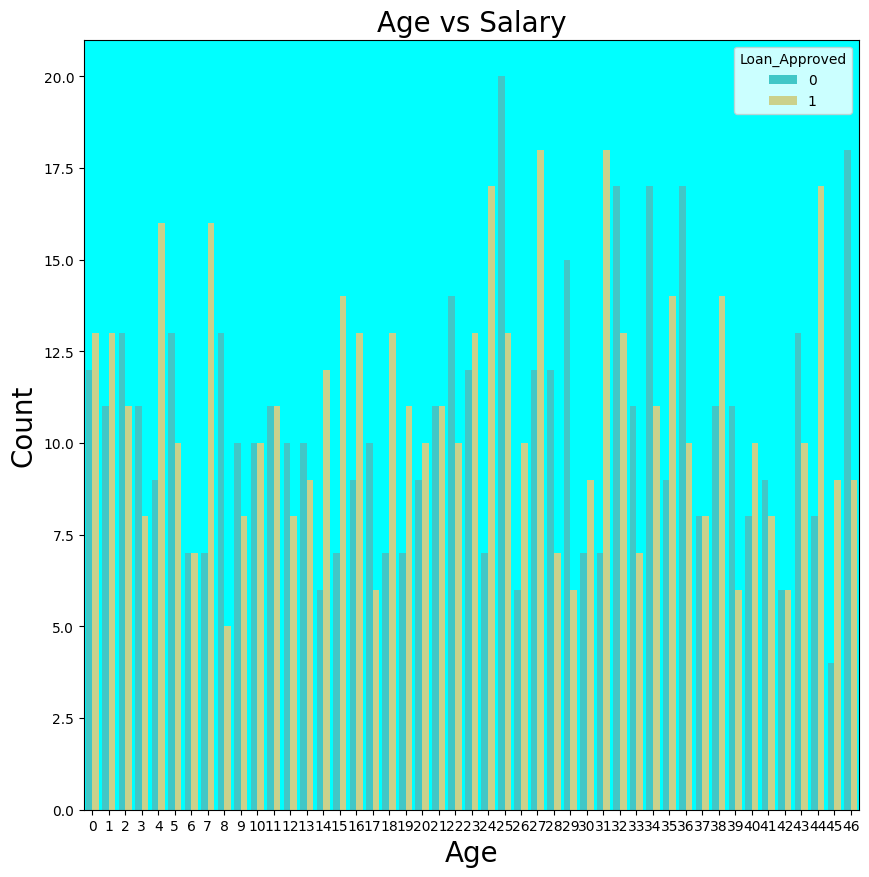

In [122]:
plt.figure(figsize=(10,10))
sns.countplot(x='Age',data=dfl,hue='Loan_Approved',palette='rainbow')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Count',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age vs Salary',fontsize=20,y=1)
plt.show()
#

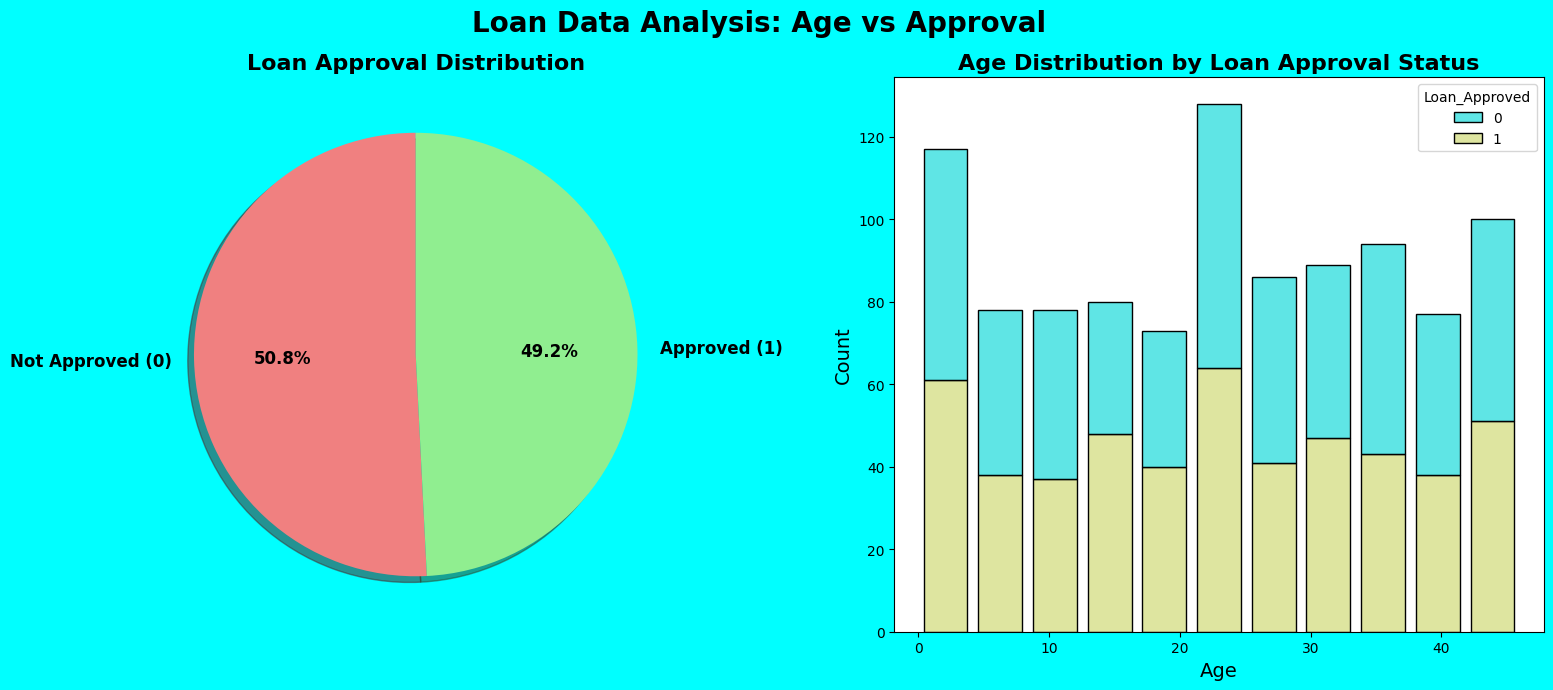

In [123]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create subplots to show both target distribution and Age vs Loan Approval
fig, axes = plt.subplots(1, 2, figsize=(16, 7), facecolor='cyan')

# 1. Pie Chart of Loan Approval
loan_counts = dfl['Loan_Approved'].value_counts()
axes[0].pie(loan_counts, labels=['Not Approved (0)', 'Approved (1)'], autopct='%1.1f%%',
           colors=['lightcoral', 'lightgreen'], shadow=True, startangle=90,
           textprops={'fontsize': 12, 'weight': 'bold'})
axes[0].set_title('Loan Approval Distribution', fontsize=16, weight='bold')

# 2. KDE/Histogram of Age grouped by Loan Approval status
sns.histplot(x='Age', data=dfl, hue='Loan_Approved', multiple='stack',
             palette='rainbow', shrink=0.8, ax=axes[1])
axes[1].set_xlabel('Age', fontsize=14)
axes[1].set_ylabel('Count', fontsize=14)
axes[1].set_title('Age Distribution by Loan Approval Status', fontsize=16, weight='bold')
axes[1].set_facecolor('white')

plt.suptitle('Loan Data Analysis: Age vs Approval', fontsize=20, y=0.98, weight='bold')
plt.tight_layout()
plt.show()

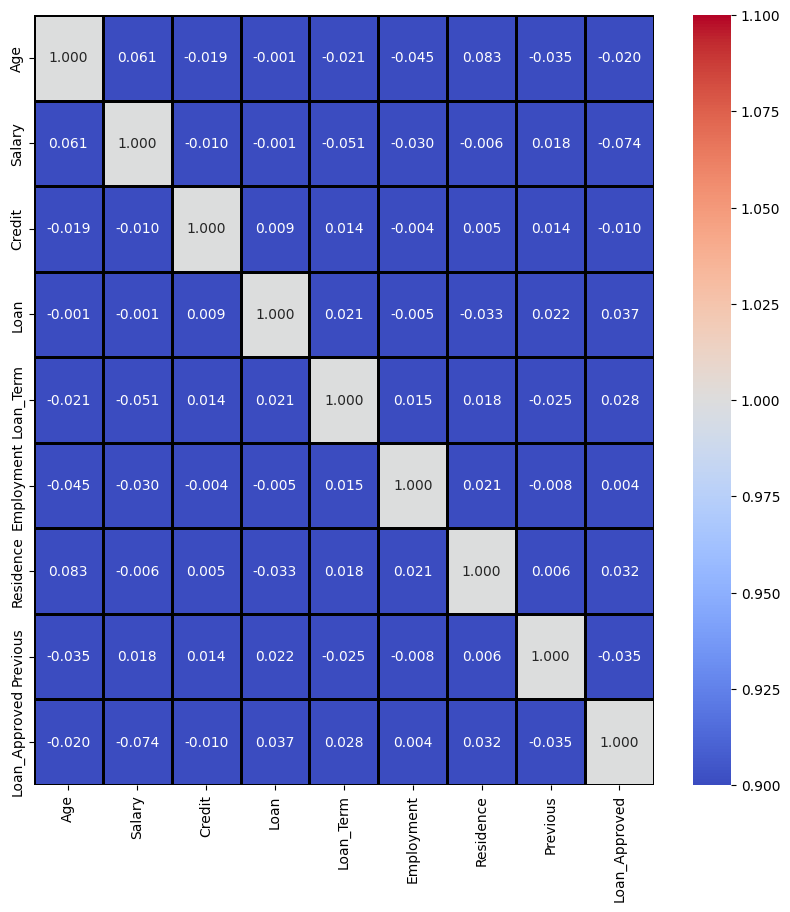

In [124]:
plt.figure(figsize=(10,10))
c_var=dfl.corr()['Loan_Approved']

sns.heatmap(dfl.corr(),annot=True,linewidths=2,linecolor='black',vmin=1.0,vmax=1.0,cmap='coolwarm',fmt='0.3f')

plt.show()

/tmp/ipykernel_399/187114716.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(x='Age',y='Salary',data=dfl,palette='rainbow')


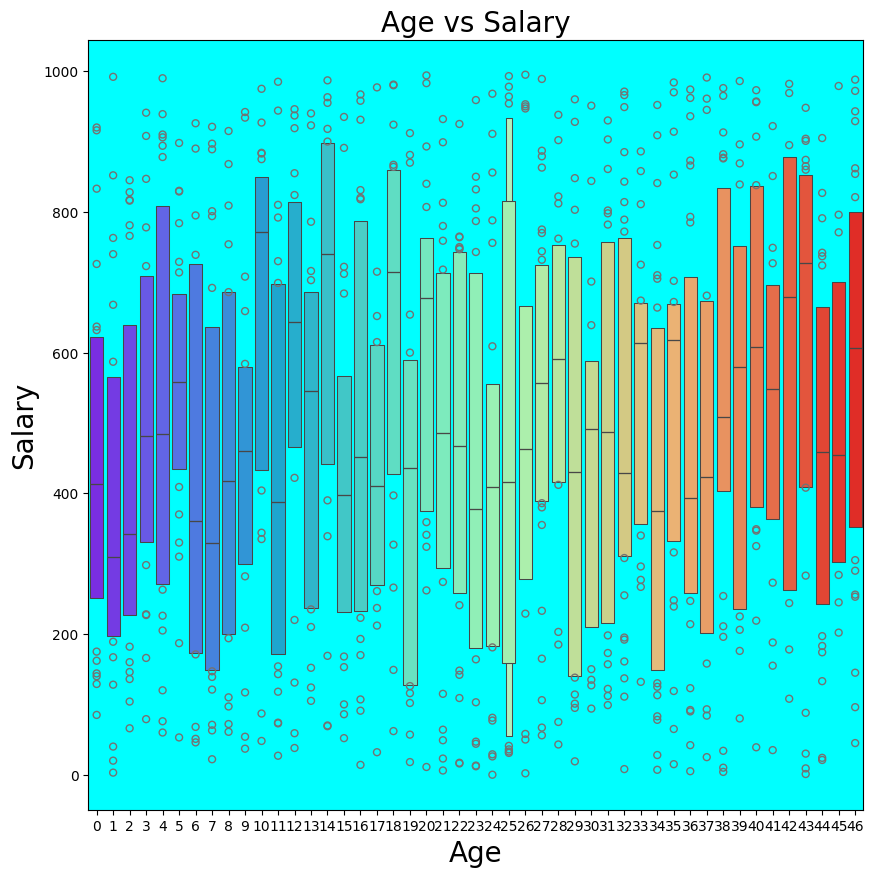

In [125]:
plt.figure(figsize=(10,10))
sns.boxenplot(x='Age',y='Salary',data=dfl,palette='rainbow')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Salary',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age vs Salary',fontsize=20,y=1)
plt.show()

In [126]:
dfl.isnull().sum(1)

,0
0,0
1,0
2,0
3,0
4,0
...,...
995,0
996,0
997,0
998,0


In [127]:
dfl.duplicated().sum()

np.int64(0)

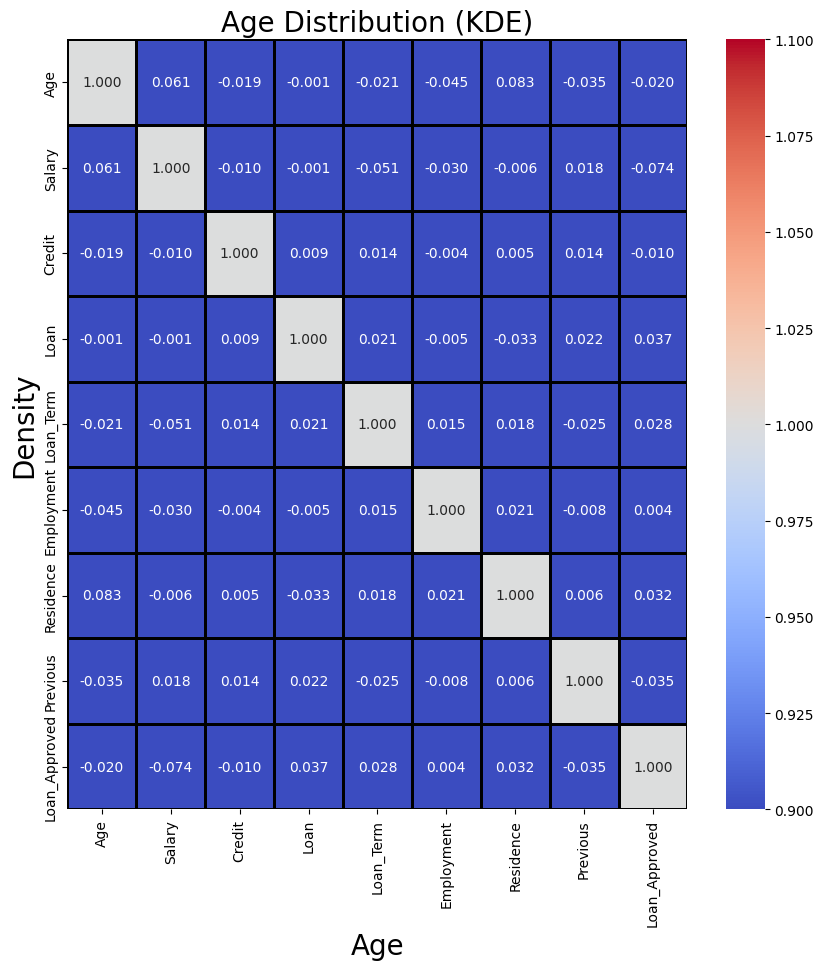

In [128]:
plt.figure(figsize=(10,10))
sns.heatmap(dfl.corr(),annot=True,linewidths=2,linecolor='black',vmin=1.0,vmax=1.0,cmap='coolwarm',fmt='0.3f')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Density',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age Distribution (KDE)',fontsize=20)
plt.show()

/tmp/ipykernel_399/3787372337.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(x='Age',data=dfl,bins=5,color='black',multiple='dodge',palette='rainbow',shrink=0.9)


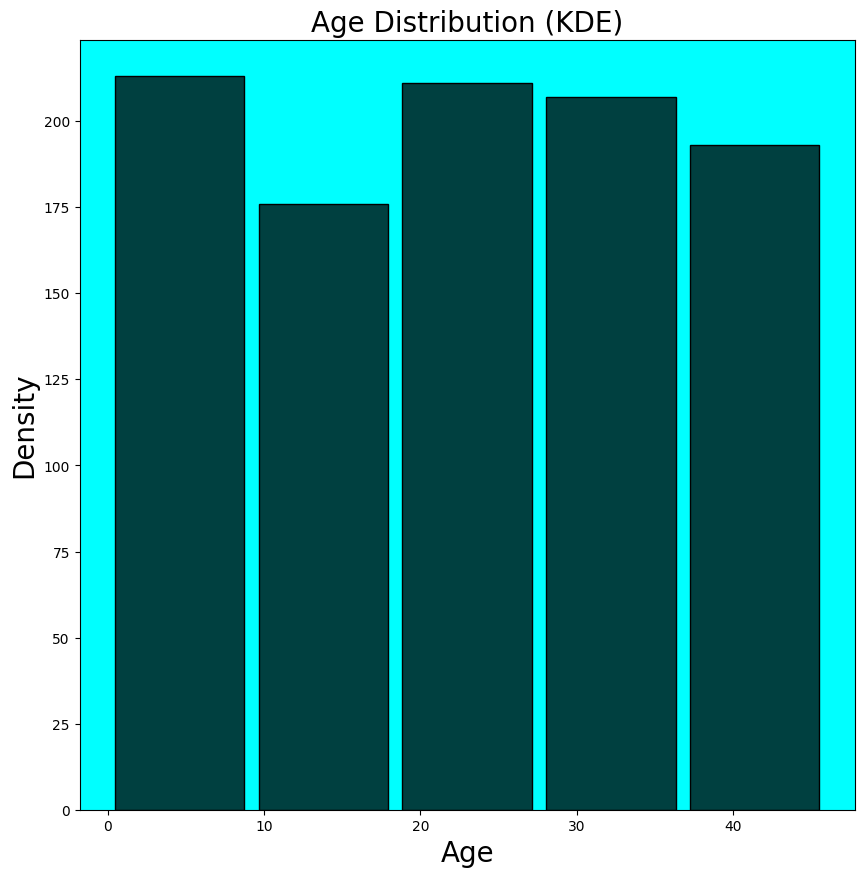

In [129]:
plt.figure(figsize=(10,10))
sns.histplot(x='Age',data=dfl,bins=5,color='black',multiple='dodge',palette='rainbow',shrink=0.9)
plt.xlabel('Age',fontsize=20)
plt.ylabel('Density',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age Distribution (KDE)',fontsize=20)
plt.show()

In [130]:
model=DecisionTreeClassifier()
model.fit(x_train,y_train)

DecisionTreeClassifier()

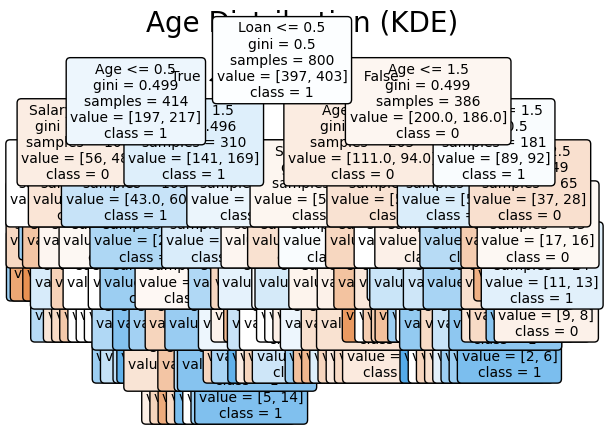

In [131]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plot_tree(model,feature_names=dfl.columns.tolist(),class_names=['0','1'],rounded=True,filled=True,fontsize=10)
plt.xlabel('Age',fontsize=20)
plt.ylabel('Density',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age Distribution (KDE)',fontsize=20)
plt.show()

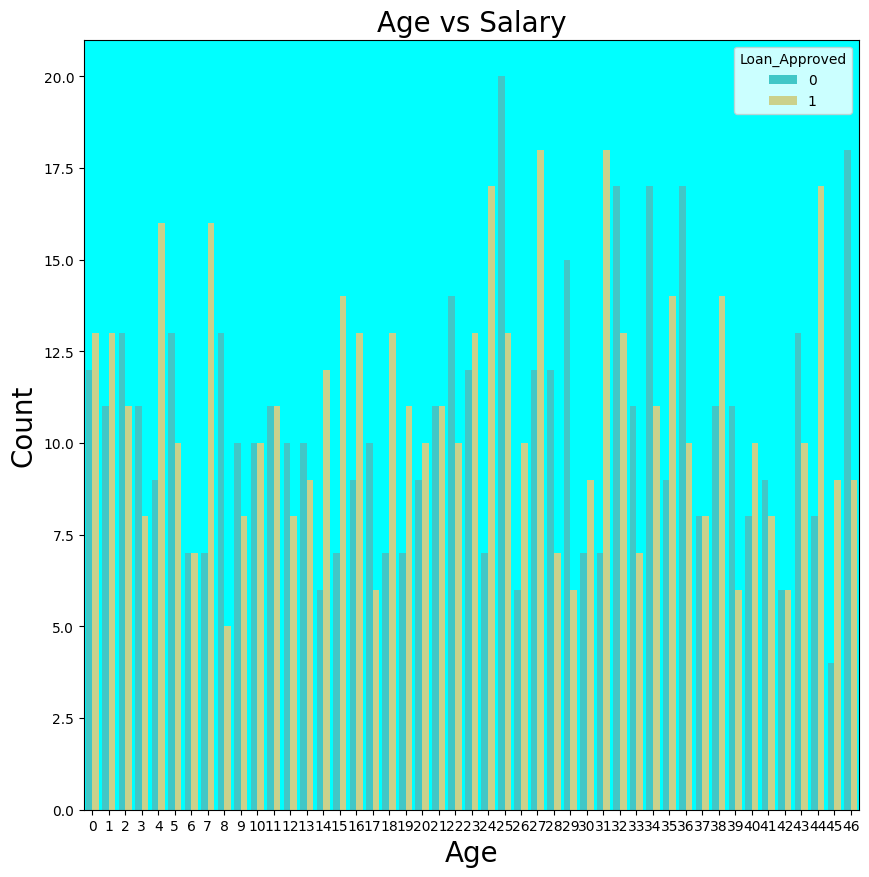

In [132]:
plt.figure(figsize=(10,10))
sns.countplot(x='Age',data=dfl,hue='Loan_Approved',palette='rainbow')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Count',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age vs Salary',fontsize=20,y=1)
plt.show()

In [133]:
model=DecisionTreeClassifier()
model.fit(x_train,y_train)
acc_full=model.score(x_train,y_train)
acc_test=model.score(x_test,y_test)
print('Full tree accuracy:',{acc_full})
print('Test tree depth  :',model.get_depth())
print('Test tree leaves:',model.get_n_leaves())


Full tree accuracy: {0.6175}
Test tree depth  : 8
Test tree leaves: 72


In [134]:
dfl.describe()

,Age,Salary,Credit,Loan,Loan_Term,Employment,Residence,Previous,Loan_Approved
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,22.986000,497.891000,576.329000,27161.882000,1.453000,1.050000,0.980000,0.468000,0.508000
std,13.497852,287.381331,157.738607,12825.343062,1.114914,0.817416,0.819922,0.499225,0.500186
min,0.000000,0.000000,300.000000,5138.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,11.000000,249.750000,442.000000,16181.750000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,24.000000,497.500000,576.000000,26633.500000,1.000000,1.000000,1.000000,0.000000,1.000000
75%,34.000000,746.250000,709.750000,38002.000000,2.000000,2.000000,2.000000,1.000000,1.000000
max,46.000000,995.000000,849.000000,49900.000000,3.000000,2.000000,2.000000,1.000000,1.000000


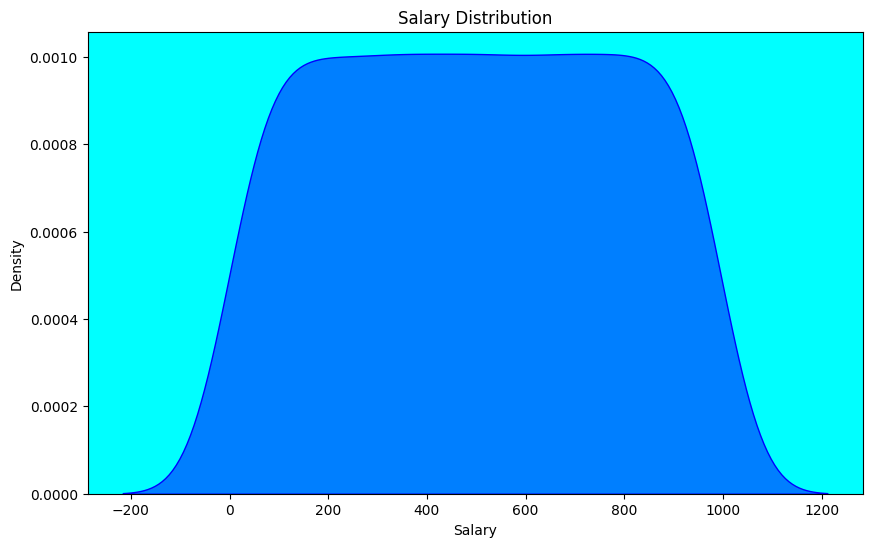

In [135]:
plt.figure(figsize=(10, 6))
sns.kdeplot(x='Salary', data=dfl, label='Salary', fill=True, color='blue', alpha=0.5)
plt.title('Salary Distribution')
plt.xlabel('Salary')
plt.ylabel('Density')
plt.gca().set_facecolor('lightblue')
plt.gca().set_facecolor('cyan')
plt.show()

/tmp/ipykernel_399/122778200.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Age',y='Salary',data=dfl,palette='rainbow')


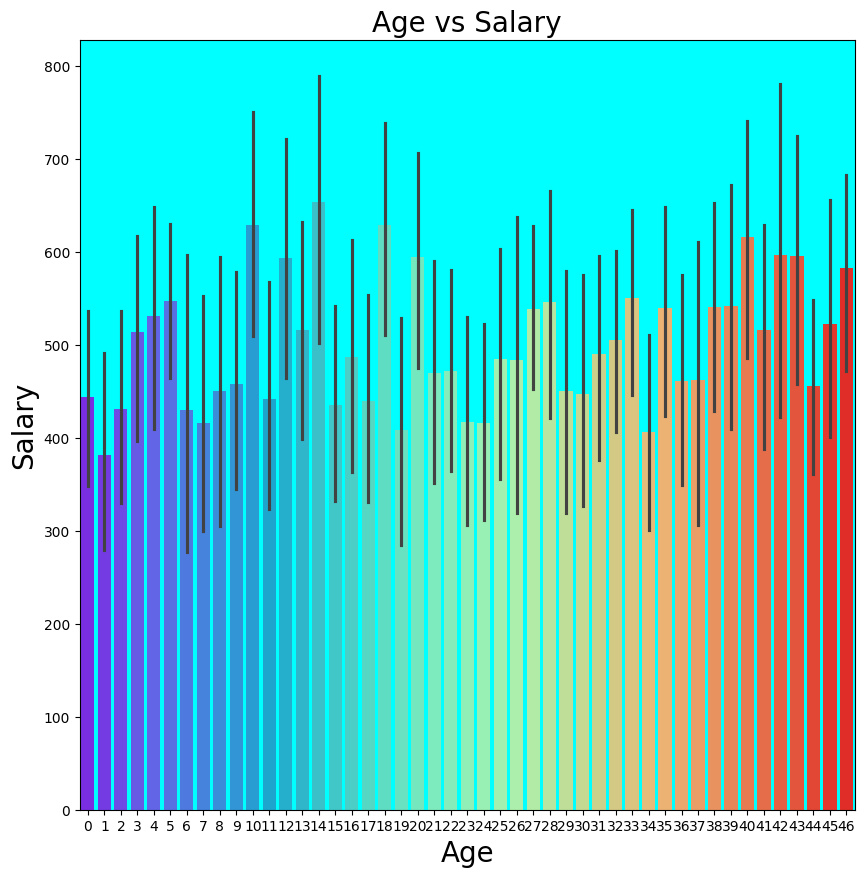

In [136]:
plt.figure(figsize=(10,10))
sns.barplot(x='Age',y='Salary',data=dfl,palette='rainbow')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Salary',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age vs Salary',fontsize=20,y=1)
plt.show()

/tmp/ipykernel_399/1399246929.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(x='Age',y='Credit',data=dfl,palette='rainbow')


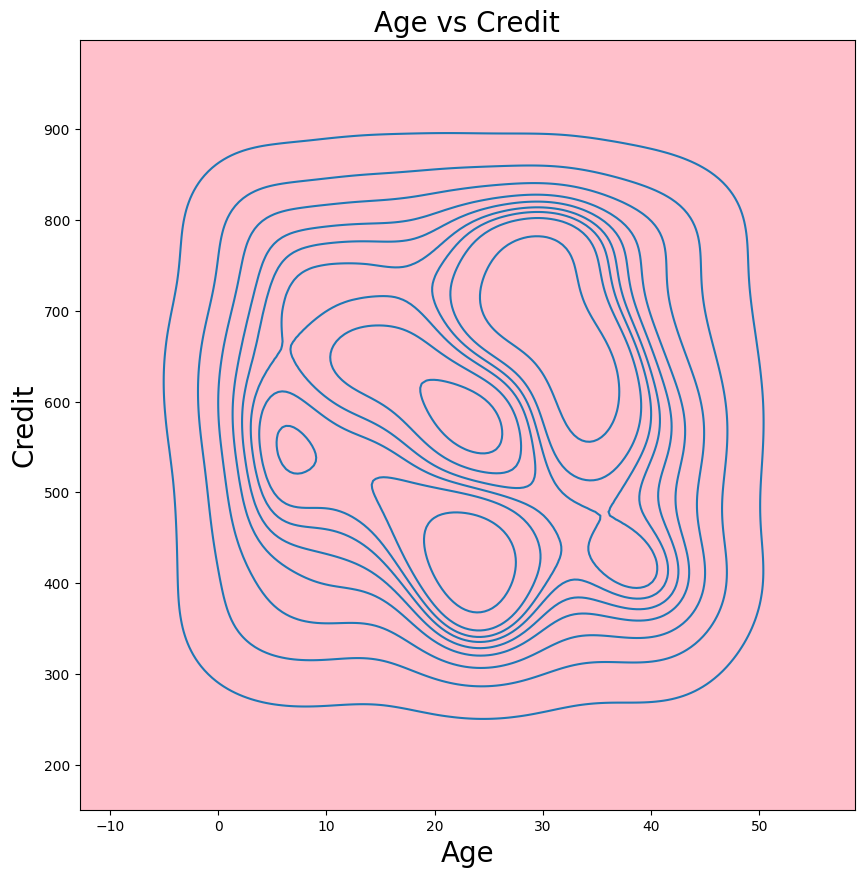

In [137]:
plt.figure(figsize=(10,10))
sns.kdeplot(x='Age',y='Credit',data=dfl,palette='rainbow')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Credit',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.gca().set_facecolor('pink')
plt.title('Age vs Credit',fontsize=20,y=1)
plt.show()

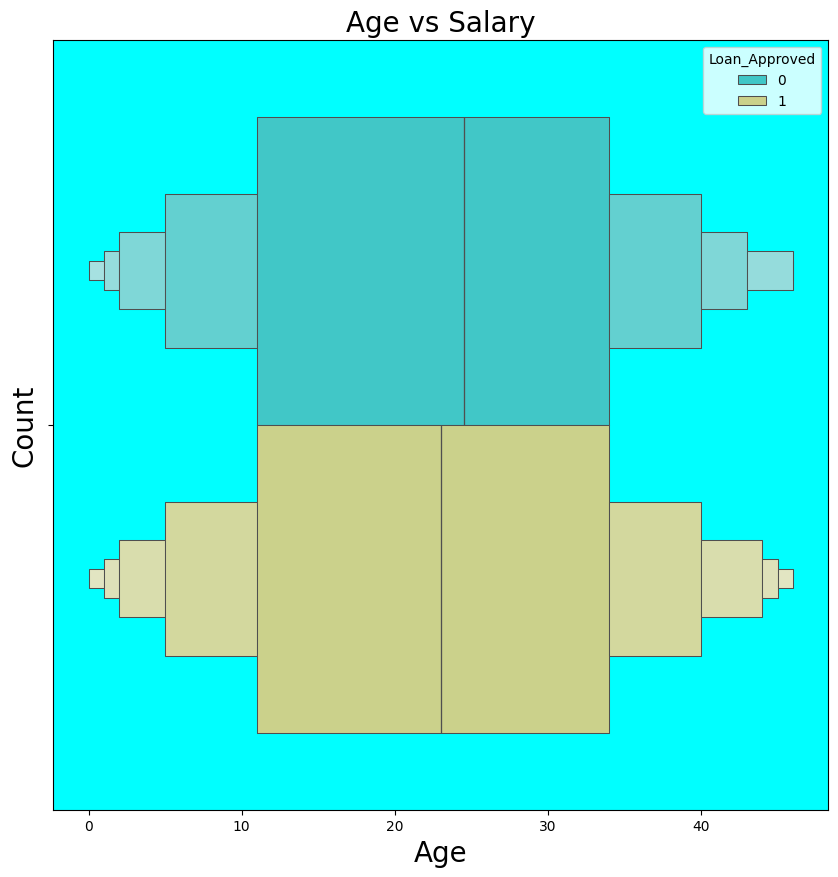

In [138]:
plt.figure(figsize=(10,10))
sns.boxenplot(x='Age',data=dfl,hue='Loan_Approved',palette='rainbow')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Count',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age vs Salary',fontsize=20,y=1)
plt.show()

/tmp/ipykernel_399/2243068862.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(x='Age',y='Salary',data=dfl,palette='rainbow')


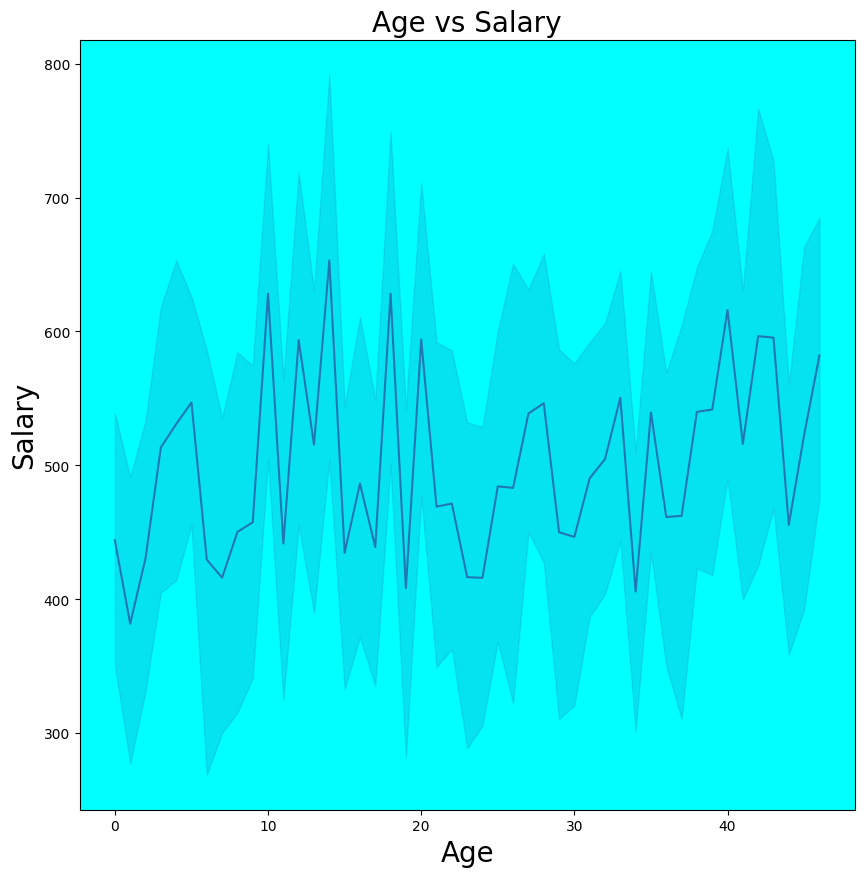

In [139]:
plt.figure(figsize=(10,10))
sns.lineplot(x='Age',y='Salary',data=dfl,palette='rainbow')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Salary',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age vs Salary',fontsize=20,y=1)
plt.show()
#

/tmp/ipykernel_399/599861464.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.displot(x='Age',data=dfl,palette='rainbow')


<Figure size 1000x1000 with 0 Axes>

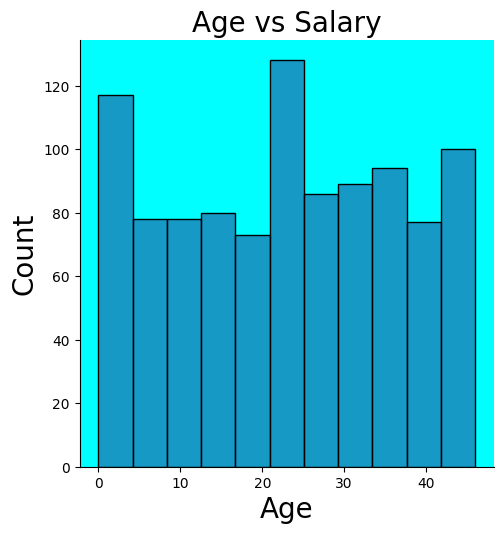

In [140]:
plt.figure(figsize=(10,10))
sns.displot(x='Age',data=dfl,palette='rainbow')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Count',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.gca().set_facecolor('cyan')
plt.title('Age vs Salary',fontsize=20,y=1)
plt.show()

In [141]:
model=DecisionTreeClassifier()
model.fit(x_train,y_train)

DecisionTreeClassifier()

In [142]:
model=DecisionTreeClassifier()
model.fit(x_train,y_train)

DecisionTreeClassifier()

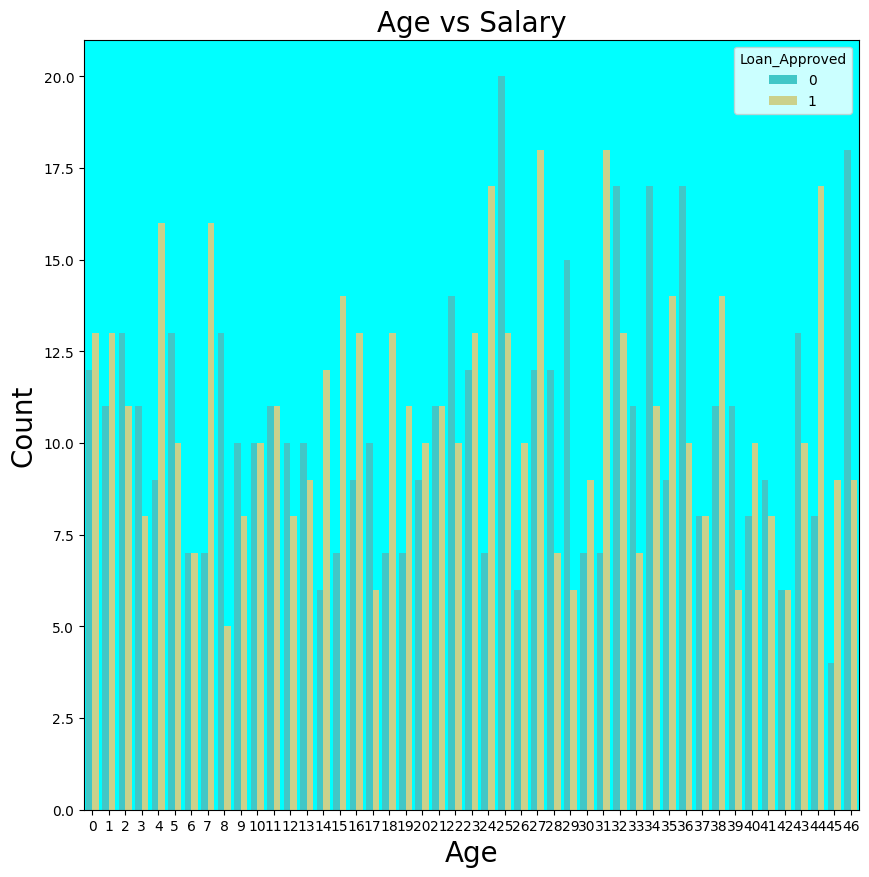

In [143]:
plt.figure(figsize=(10,10))
sns.countplot(x='Age',data=dfl,hue='Loan_Approved',palette='rainbow')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Count',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.gca().set_facecolor('cyan')
plt.title('Age vs Salary',fontsize=20,y=1)
plt.show()

In [144]:
dfl.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Age            1000 non-null   int64
 1   Salary         1000 non-null   int64
 2   Credit         1000 non-null   int64
 3   Loan           1000 non-null   int64
 4   Loan_Term      1000 non-null   int64
 5   Employment     1000 non-null   int64
 6   Residence      1000 non-null   int64
 7   Previous       1000 non-null   int64
 8   Loan_Approved  1000 non-null   int64
dtypes: int64(9)
memory usage: 70.4 KB


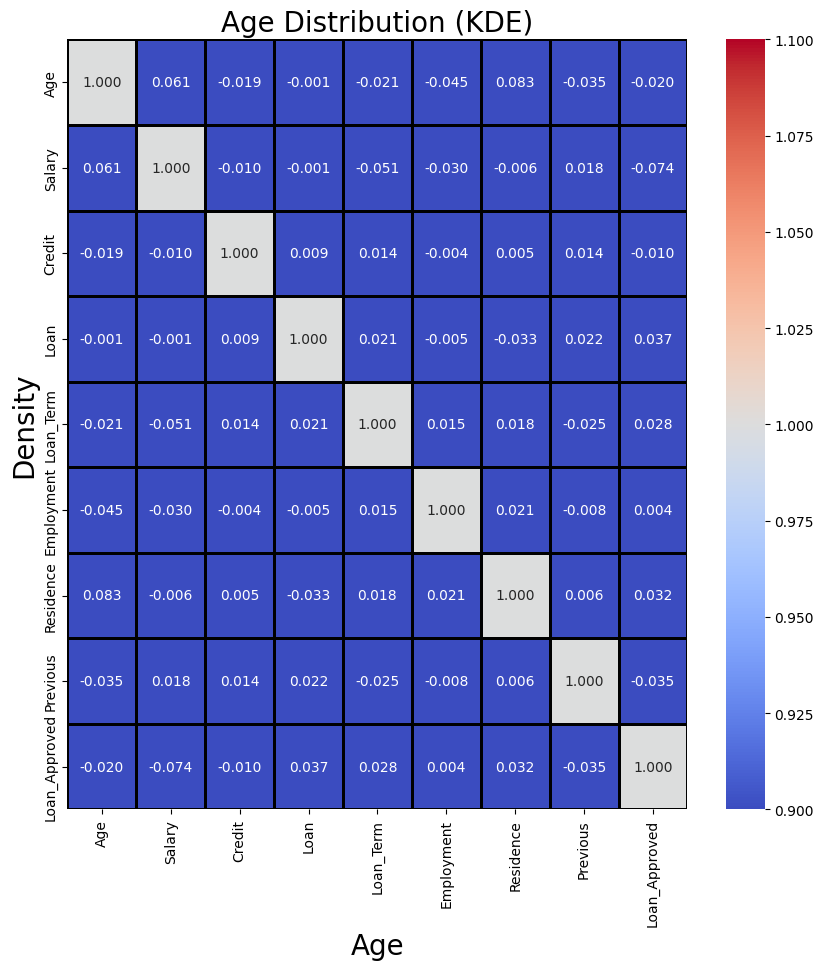

In [145]:
 plt.figure(figsize=(10,10))
 sns.heatmap(dfl.corr(),annot=True,linewidths=2,linecolor='black',vmin=1.0,vmax=1.0,cmap='coolwarm',fmt='0.3f')
 plt.xlabel('Age',fontsize=20)
 plt.ylabel('Density',fontsize=20)
 plt.gca().set_facecolor('cyan')
 plt.title('Age Distribution (KDE)',fontsize=20)
 plt.show()

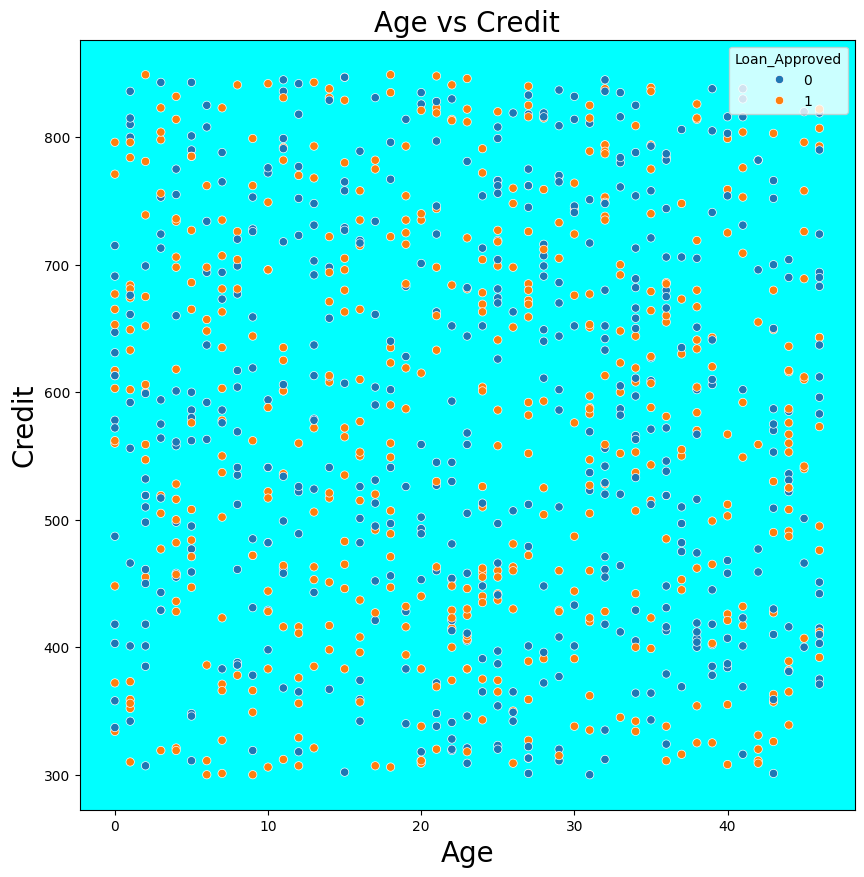

In [146]:
plt.figure(figsize=(10,10))
sns.scatterplot(x='Age',y='Credit',data=dfl,color='red',hue='Loan_Approved')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Credit',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age vs Credit',fontsize=20,y=1)
plt.show()

In [147]:
dfl.describe()

,Age,Salary,Credit,Loan,Loan_Term,Employment,Residence,Previous,Loan_Approved
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,22.986000,497.891000,576.329000,27161.882000,1.453000,1.050000,0.980000,0.468000,0.508000
std,13.497852,287.381331,157.738607,12825.343062,1.114914,0.817416,0.819922,0.499225,0.500186
min,0.000000,0.000000,300.000000,5138.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,11.000000,249.750000,442.000000,16181.750000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,24.000000,497.500000,576.000000,26633.500000,1.000000,1.000000,1.000000,0.000000,1.000000
75%,34.000000,746.250000,709.750000,38002.000000,2.000000,2.000000,2.000000,1.000000,1.000000
max,46.000000,995.000000,849.000000,49900.000000,3.000000,2.000000,2.000000,1.000000,1.000000


/tmp/ipykernel_399/1448876998.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Age',y='Salary',data=dfl,palette='rainbow')


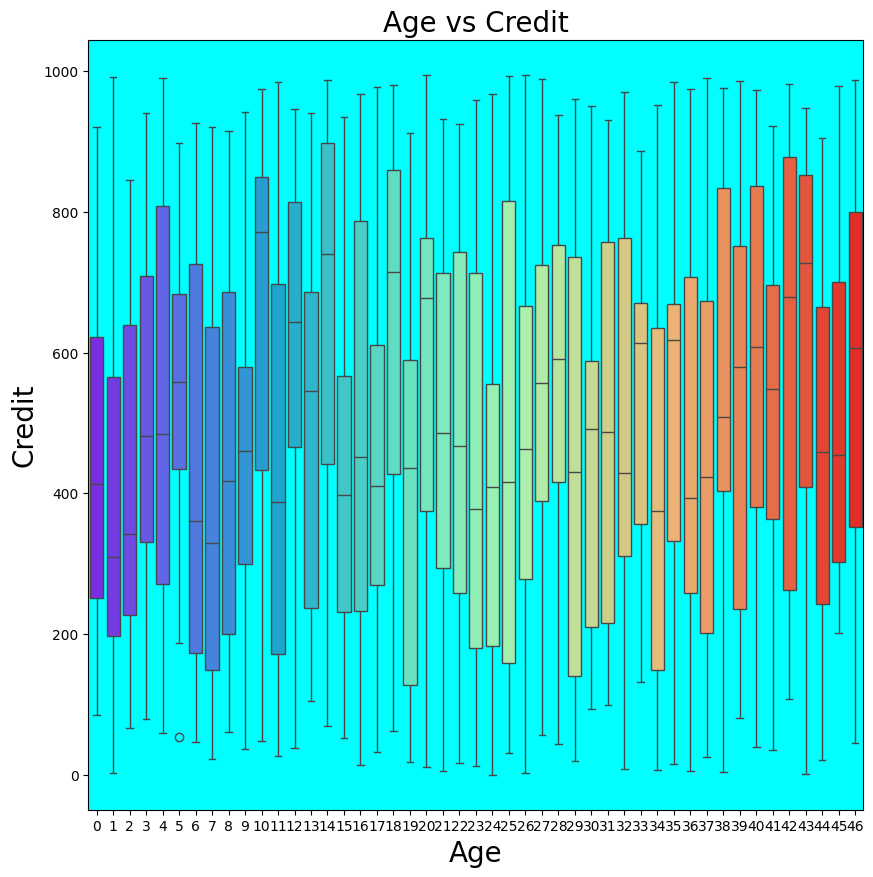

In [148]:
plt.figure(figsize=(10,10))
sns.boxplot(x='Age',y='Salary',data=dfl,palette='rainbow')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Credit',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age vs Credit',fontsize=20,y=1)
plt.show()

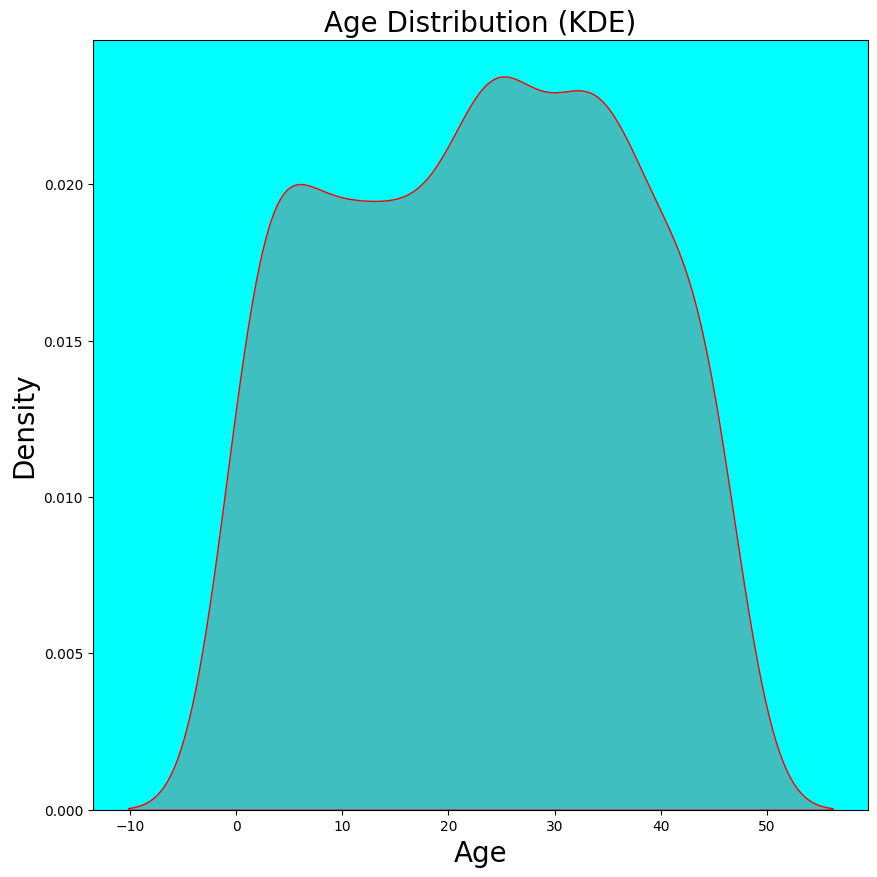

In [149]:
plt.figure(figsize=(10,10))
sns.kdeplot(x='Age',data=dfl,color='red',fill=True)
plt.xlabel('Age',fontsize=20)
plt.ylabel('Density',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age Distribution (KDE)',fontsize=20,y=1)
plt.show()

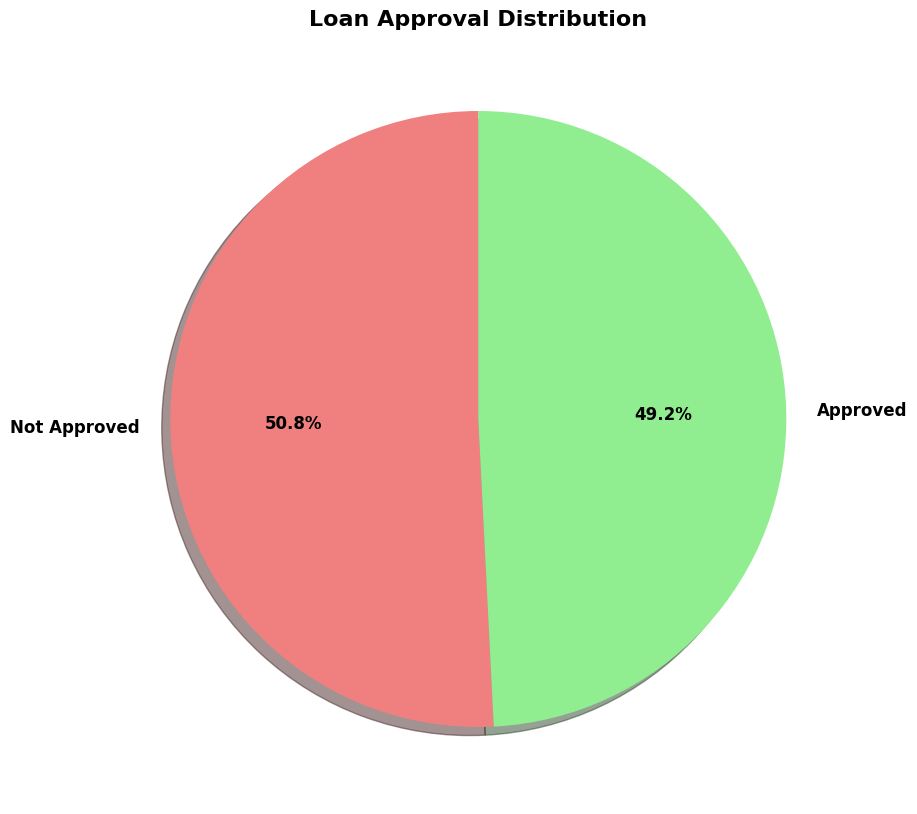

In [150]:
plt.figure(figsize=(10,10))
plt.pie(dfl['Loan_Approved'].value_counts(),labels=['Not Approved','Approved'],autopct='%1.1f%%',colors=['lightcoral','lightgreen'],shadow=True,startangle=90,textprops={'fontsize':12,'weight':'bold'})
plt.title('Loan Approval Distribution',fontsize=16,weight='bold')
plt.show()

/tmp/ipykernel_399/1192013016.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Age',y='Salary',data=dfl,palette='rainbow')


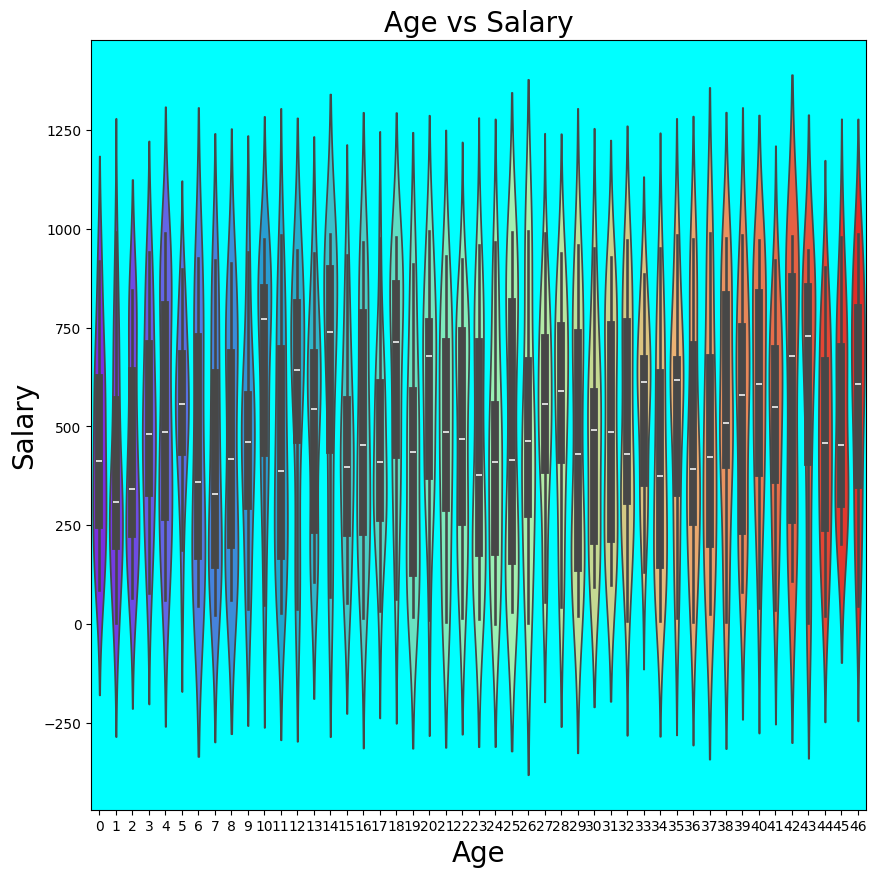

In [151]:
plt.figure(figsize=(10,10))
sns.violinplot(x='Age',y='Salary',data=dfl,palette='rainbow')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Salary',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age vs Salary',fontsize=20,y=1)
plt.show()
#

/tmp/ipykernel_399/383880807.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(x='Age',y='Salary',data=dfl,palette='rainbow')


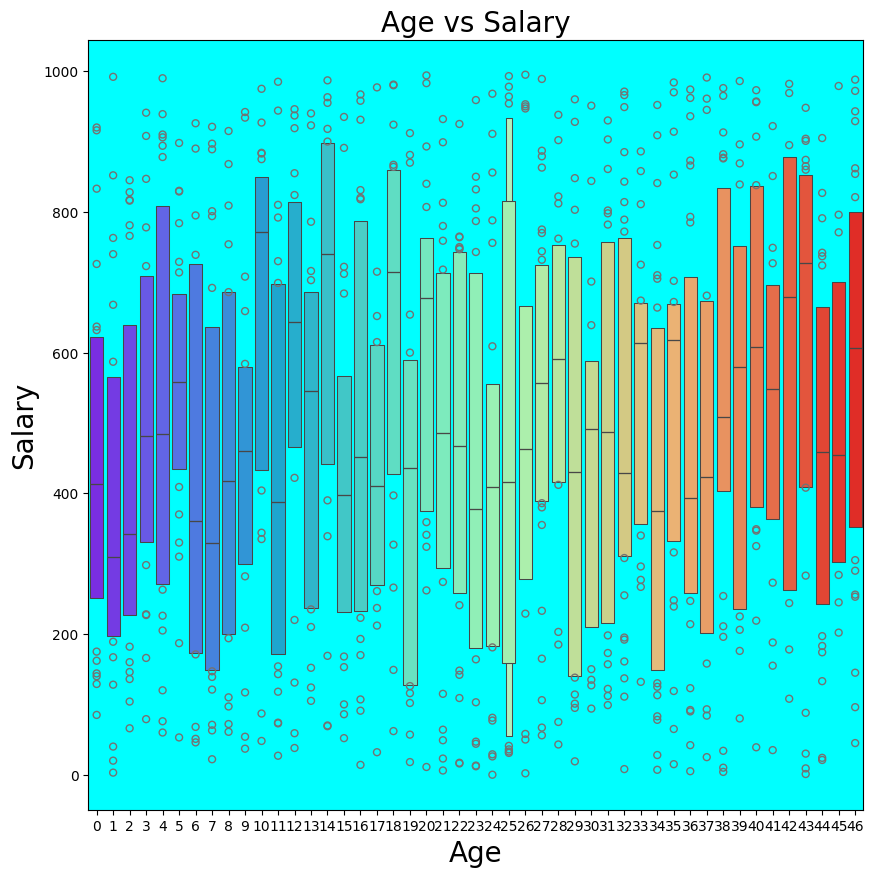

In [152]:
plt.figure(figsize=(10,10))
sns.boxenplot(x='Age',y='Salary',data=dfl,palette='rainbow')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Salary',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age vs Salary',fontsize=20,y=1)
plt.show()


In [153]:
dfl.isnull().sum()

,0
Age,0
Salary,0
Credit,0
Loan,0
Loan_Term,0
Employment,0
Residence,0
Previous,0
Loan_Approved,0


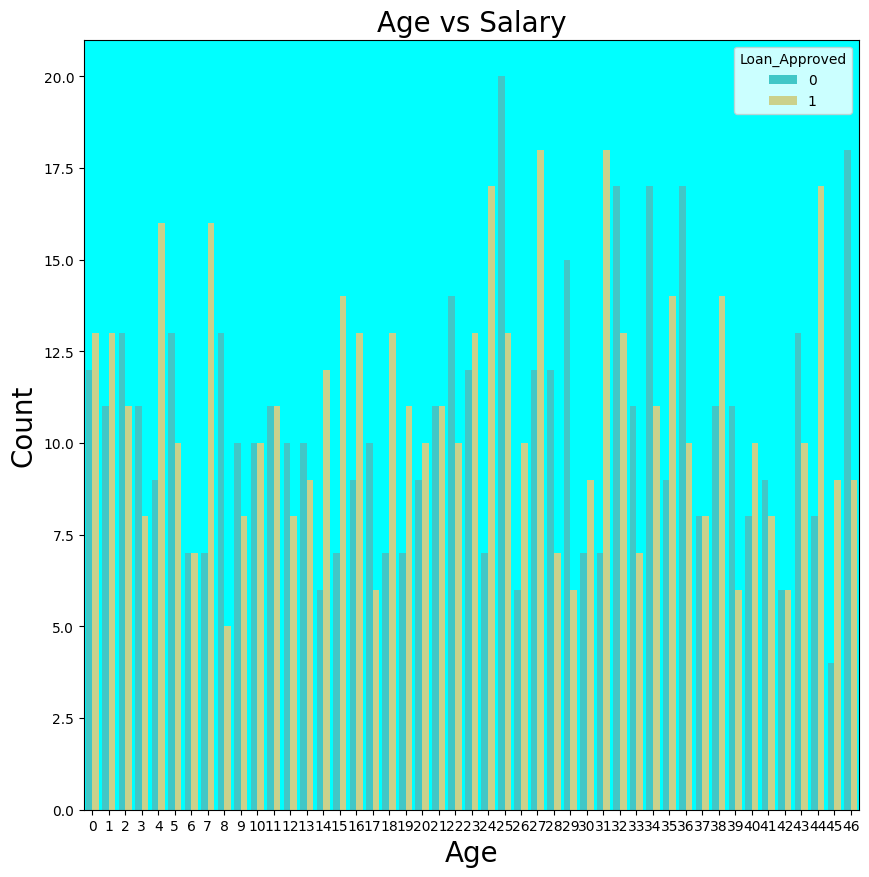

In [154]:
plt.figure(figsize=(10,10))
sns.countplot(x='Age',data=dfl,hue='Loan_Approved',palette='rainbow')
plt.xlabel('Age',fontsize=20)
plt.ylabel('Count',fontsize=20)
plt.gca().set_facecolor('cyan')
plt.title('Age vs Salary',fontsize=20,y=1)
plt.show()
#